# NGC4654 stellar mass surface density and VIVA sector

This notebook repeats the spatial and angular analyses of [the SFR excess notebook](20261117_NGC4654_SFR_excess_Fourier_VIVA.ipynb) with the NGC4654 stellar mass surface density as the response, \(y=\log_{10}[\Sigma_\star/(M_\odot\,\mathrm{kpc}^{-2})]\). It reads the inclination-corrected 7000 SFH16 mass map without a reference-relation subtraction or width normalization. The usable stellar footprint requires a finite mass density, a valid continuum BINID, an unmasked spaxel, and stellar post-fit S/N > 25. No emission-line or SF selection is applied. Fit coefficients and RMSE are in dex; RSS is in dex squared. Run the cells from top to bottom.

$$
\begin{aligned}
\widehat y_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{c_1\cos\phi_i+s_1\sin\phi_i}_{m=1}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

Here \(i\) indexes a continuum bin, \(a\) is its annulus, \(r_i=R_i/R_e\), \(r_a\) is the annulus midpoint, and \(\phi_i\) is the bin's sky PA measured east of north. The shared \(m=1\) coefficients give \(A=\sqrt{c_1^2+s_1^2}\) and \(\theta=\operatorname{atan2}(s_1,c_1)\) modulo \(360^\circ\). Setting \(c_1=s_1=0\) and refitting the annular coefficients gives the comparison model without \(m=1\).

Each continuum BINID contributes one equally weighted observation: its mean log mass density over usable spaxels, placed at the geometric centroid of all native spaxels with that BINID. The radial cut applies to the centroid. Fits retain four \(0.4R_e\) annuli through \(1.6R_e\), with an intercept, radial slope and an \(m=2\) pair per populated annulus. The observed arrow maps show the usable native stellar spaxels. Each companion model map displays the full fitted log stellar-mass surface density of each fitted continuum BINID on its usable spaxels. The observed and fitted maps use the same sky limits, and the mass-density panels use the observed colour scale. Heatmaps and angular diagnostics use continuum-bin means. The peak outer cell is selected from the raw bin means, so it can reflect a radial gradient as well as angular structure. The Fourier fit retains the whole-BINID bootstrap and restricted wild bootstrap.

The arrow is the positive direction of the fitted angular term after accounting for the annular terms. The VIVA overlay is the same coarse northwest compass sector (sky PA \(270^\circ\)–\(360^\circ\), east of north) used in the SFR notebook.

Each model grid shows the fitted terms in the order \(m=0\), \(m=0+1\), \(m=0+2\), and \(m=0+1+2\). Here \(m=0\) is the annular intercept and radial slope, and the \(m=0+1\) panel adds the fitted directional term to the radial baseline, including the alternative angular templates. All panels use coefficients from the same full fit. The \(m=0+2\) panel subtracts the directional term from that fit.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8_7000'
TARGET = 'NGC4654'
SNR_POSTFIT_MIN = 25.0
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
NGC4654_FIT_EDGES = np.linspace(0.0, 1.6, 5)
MASS_LABEL = r'$\log_{10}[\Sigma_\star/(M_\odot\,\mathrm{kpc}^{-2})]$'

mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 22, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def first_product_existing(product_id, names):
    for folder_suffix in ('', '_SFH16'):
        folder = DATA_ROOT / f'{product_id}{folder_suffix}'
        prefixes = (product_id, f'{product_id}{folder_suffix}')
        candidates = [f'{prefix}_{name}' for prefix in prefixes for name in names]
        found = first_existing(folder, candidates)
        if found is not None:
            return found
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def elliptical_radius_from_offsets(east, north, component):
    pa = np.deg2rad(float(component.pa_deg_east_of_north))
    major = east * np.sin(pa) + north * np.cos(pa)
    minor = east * np.cos(pa) - north * np.sin(pa)
    return np.sqrt((major / float(component.a_re_arcsec)) ** 2
                   + (minor / float(component.b_re_arcsec)) ** 2)


geometry_by_galaxy = pd.read_csv(GEOMETRY_PATH).set_index('galaxy', verify_integrity=True)


In [3]:
component = geometry_by_galaxy.loc[TARGET]
paths = {
    'mass': first_product_existing(TARGET, ['spatial_binning_maps_further.fits',
                                            'SPATIAL_BINNING_maps_further.fits']),
    'sfh': first_product_existing(TARGET, ['sfh_maps.fits']),
    'mask': first_product_existing(TARGET, ['mask.fits']),
}
missing = [key for key, path in paths.items() if path is None]
if missing:
    raise FileNotFoundError(f'{TARGET}: missing {", ".join(missing)} under {DATA_ROOT}')

mass, mass_header = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
continuum_binid, binid_header = read_map(paths['mass'], 'BINID')
snr_postfit, snr_header = read_map(paths['sfh'], 'SNR_POSTFIT')
for label, array, header in [('continuum BINID', continuum_binid, binid_header),
                             ('SFH post-fit S/N', snr_postfit, snr_header)]:
    if array.shape != mass.shape:
        raise ValueError(f'{TARGET}: stellar mass and {label} shapes differ')
    check_wcs(mass_header, header, mass.shape, f'{TARGET}: stellar mass / {label}')
with fits.open(paths['mask']) as hdus:
    flat_mask = np.asarray(hdus['MASKFILE'].data['MASK'])
if flat_mask.size != mass.size:
    raise ValueError(f'{TARGET}: spatial mask length mismatch')
spatial_mask = flat_mask.reshape(mass.shape)

native = (np.isfinite(continuum_binid) & (continuum_binid >= 0)
          & (continuum_binid == np.floor(continuum_binid)))
usable = (native & np.isfinite(mass) & (spatial_mask == 0)
          & np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN))
if not usable.any():
    raise ValueError(f'{TARGET}: no usable stellar mass spaxels')
ngc4654_native_binid = continuum_binid
native_wcs = WCS(mass_header).celestial
native_y, native_x = np.nonzero(native)
ra, dec = native_wcs.pixel_to_world_values(native_x, native_y)
east, north = tangent_offsets_arcsec(ra, dec, component.center_ra_deg, component.center_dec_deg)
pixel_binid = continuum_binid[native].astype(np.int64)
bin_ids, bin_index, bin_count = np.unique(pixel_binid, return_inverse=True, return_counts=True)
centre_east = np.bincount(bin_index, weights=east) / bin_count
centre_north = np.bincount(bin_index, weights=north) / bin_count
ngc4654_bin_geometry = pd.DataFrame(dict(
    binid=bin_ids, east=centre_east, north=centre_north, N_native=bin_count,
    r=elliptical_radius_from_offsets(centre_east, centre_north, component)))

keep = usable[native]
ngc4654_map = pd.DataFrame(dict(east=east[keep], north=north[keep], binid=pixel_binid[keep],
                                log_sigma_star=mass[usable]))
display(pd.Series({key: str(path) for key, path in paths.items()}, name='Input product').to_frame())


,Input product
mass,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
sfh,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
mask,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...


In [4]:
# Aggregate the stellar map in log space, using one observation per BINID.
bin_mass = ngc4654_map.groupby('binid').log_sigma_star.agg(
    log_sigma_star='mean', N_mass='size').reset_index()
ngc4654_bins = ngc4654_bin_geometry.merge(bin_mass, on='binid', validate='one_to_one')
assert ngc4654_bins.N_mass.sum() == usable.sum()
assert ngc4654_bins.N_mass.le(ngc4654_bins.N_native).all()

# Share the native mass map's 1st–99th percentile colour scale across the sky maps and heatmaps.
MASS_VMIN, MASS_VMAX = np.percentile(ngc4654_map.log_sigma_star, [1, 99])
print(f'{len(ngc4654_map):,} usable stellar spaxels in {len(ngc4654_bins):,} continuum bins')
print(f'Mass colour limits: {MASS_VMIN:.2f} to {MASS_VMAX:.2f} dex')


555,079 usable stellar spaxels in 23,827 continuum bins
Mass colour limits: 6.78 to 8.72 dex


In [5]:
from scipy.optimize import least_squares


def annular_radial_term(design, coefficients):
    """Evaluate the intercept and slope columns of each four-term annular block."""
    radial = np.arange(len(coefficients)) % 4 < 2
    return np.einsum('ij,j->i', design[:, radial], coefficients[radial])


def fit_ngc4654_stellar_mass(frame):
    # Fourier model and BINID resampling from the reference notebook.
    edges = NGC4654_FIT_EDGES
    centers = (edges[:-1] + edges[1:]) / 2
    MIN_BINS_FIT = 20
    MAX_DESIGN_CONDITION = 1e6
    frame = frame.copy()
    frame['theta'] = np.where(np.hypot(frame.east, frame.north) > 0,
        np.arctan2(frame.east, frame.north) % (2 * np.pi), np.nan)
    valid = (np.isfinite(frame.binid) & (frame.binid >= 0)
             & (frame.binid == np.floor(frame.binid))
             & np.isfinite(frame.theta) & frame.r.between(edges[0], edges[-1]))
    native = frame.loc[valid].copy()
    if native.empty:
        raise ValueError(f'NGC4654: no continuum bins with stellar mass and valid sky angles within {edges[-1]:g} Re')
    native['binid'] = native.binid.astype(np.int64)
    # Include the outer endpoint in the final annulus.
    native['annulus'] = np.minimum(
        np.searchsorted(edges, native.r, side='right') - 1, len(centers) - 1)
    coverage_rows = []
    for annulus, bins in native.groupby('annulus'):
        sectors = np.floor(bins.theta.to_numpy() / (2 * np.pi) * 12)
        coverage_rows.append(dict(annulus=annulus, N_mass=int(bins.N_mass.sum()),
                                  N_BINID=len(bins), sectors=np.unique(sectors).size))
    coverage = pd.DataFrame(coverage_rows)

    def native_design(frame, annuli):
        cols=[]
        for a in annuli:
            take=frame.annulus.eq(a).to_numpy(float)
            cols.extend([take,take*(frame.r.to_numpy()-centers[a]),
                take*np.cos(2*frame.theta),take*np.sin(2*frame.theta)])
        cols.extend([np.cos(frame.theta), np.sin(frame.theta)])
        return np.column_stack(cols)

    def levmar_factor(R, values):
        """Minimize ||R beta-values|| with Levenberg-Marquardt."""
        result=least_squares(lambda beta: np.einsum('ij,j->i',R,beta)-values, np.zeros(R.shape[1]),
            jac=lambda beta: R, method='lm', x_scale='jac',
            ftol=1e-12, xtol=1e-12, gtol=1e-12, max_nfev=200)
        if not result.success or not np.isfinite(result.x).all():
            raise RuntimeError('Levenberg-Marquardt Fourier fit failed: '+result.message)
        return result.x

    def levmar_gram(G, rhs):
        """Cholesky compression preserves the least-squares minimum."""
        R=np.linalg.cholesky(G).T
        return levmar_factor(R,np.linalg.solve(R.T,rhs))

    def fit_native_fourier(frame,value,nboot=499,nnull=999,seed=20261012):
        f=frame.loc[np.isfinite(frame[value])].copy()
        annuli=sorted(f.annulus.unique())
        labels,ix=np.unique(f.binid,return_inverse=True)
        if len(labels)<MIN_BINS_FIT: raise ValueError('Too few BINIDs for Fourier inference')
        X=native_design(f,annuli)
        y=f[value].to_numpy(float)
        rank=np.linalg.matrix_rank(X)
        condition=np.linalg.cond(X)
        if rank!=X.shape[1] or condition>MAX_DESIGN_CONDITION:
            raise ValueError('Rank-deficient or poorly conditioned Fourier fit')
        q,R=np.linalg.qr(X,mode="reduced")
        beta=levmar_factor(R,np.einsum('ni,n->i',q,y))
        p=X.shape[1]
        # BINID sufficient statistics allow resampling bin observations without repeated large fits.
        gb=np.empty((len(labels),p,p)); hb=np.empty((len(labels),p))
        for j in range(p):
            hb[:,j]=np.bincount(ix,weights=X[:,j]*y,minlength=len(labels))
            for k in range(j+1):
                gb[:,j,k]=gb[:,k,j]=np.bincount(ix,weights=X[:,j]*X[:,k],minlength=len(labels))
        G=gb.sum(axis=0); h=hb.sum(axis=0)
        Rfull=np.linalg.cholesky(G).T; Rnull=np.linalg.cholesky(G[:-2,:-2]).T
        beta0=levmar_factor(Rnull,np.linalg.solve(Rnull.T,h[:-2]))
        fitted=np.einsum('ij,j->i',X,beta)
        fitted0=np.einsum('ij,j->i',X[:,:-2],beta0)
        rss=np.sum((y-fitted)**2); rss0=np.sum((y-fitted0)**2)
        gain=max(0.,rss0-rss)
        def explained_rss(rhs):
            full=levmar_factor(Rfull,np.linalg.solve(Rfull.T,rhs))
            without=levmar_factor(Rnull,np.linalg.solve(Rnull.T,rhs[:-2]))
            return np.array([
                2 * (rhs @ full) - full @ G @ full,
                2 * (rhs[:-2] @ without) - without @ G[:-2, :-2] @ without,
            ])

        def improvement(rhs):
            full, without = explained_rss(rhs)
            return full - without
        np.testing.assert_allclose(gain,improvement(h),rtol=1e-7,atol=1e-7)
        rng=np.random.default_rng(seed)
        draws=[]
        for _ in range(nboot):
            mult=np.bincount(rng.integers(len(labels),size=len(labels)),minlength=len(labels))
            gg=np.einsum('b,bij->ij',mult,gb); hh=np.einsum('b,bi->i',mult,hb)
            if np.linalg.cond(gg)>MAX_DESIGN_CONDITION**2: continue
            try: draws.append(levmar_gram(gg,hh)[-2:])
            except np.linalg.LinAlgError: continue
        if len(draws)<.9*nboot: raise ValueError('More than 10% BINID bootstrap fits failed')
        draws=np.asarray(draws)
        score=np.column_stack([np.bincount(ix,weights=X[:,j]*(y-fitted0),minlength=len(labels)) for j in range(p)])
        null_mean=np.einsum('ij,j->i',G[:,:-2],beta0)
        null=np.array([improvement(null_mean+np.einsum('b,bi->i',rng.choice([-1.,1.],len(labels)),score)) for _ in range(nnull)])
        amp=float(np.hypot(*beta[-2:])); phase=float(np.arctan2(beta[-1],beta[-2]))
        boot_amp=np.hypot(draws[:,0],draws[:,1]); boot_phase=np.arctan2(draws[:,1],draws[:,0])
        phase_offsets = (boot_phase - phase + np.pi) % (2 * np.pi) - np.pi

        # Compare both models with a single constant using the same BINID draws.
        constant = y.mean()
        constant_rss = np.sum((y - constant)**2)
        if constant_rss == 0:
            raise ValueError('NGC4654: zero variance in the Fourier sample')
        constant_rhs = X.sum(axis=0) * constant
        constant_score = np.column_stack([
            np.bincount(ix, weights=X[:, j] * (y - constant), minlength=len(labels))
            for j in range(p)
        ])
        overall_rng = np.random.default_rng(seed + 100)
        overall_null = np.empty((nnull, 2))
        for k in range(nnull):
            signs = overall_rng.choice([-1., 1.], len(labels))
            rhs = constant_rhs + np.einsum('b,bi->i', signs, constant_score)
            constant_gain = rhs[:-2:4].sum()**2 / len(y)
            overall_null[k] = explained_rss(rhs) - constant_gain
        observed_gains = constant_rss - np.array([rss, rss0])
        p_overall = (1 + (overall_null >= observed_gains - 1e-9).sum(axis=0)) / (nnull + 1)
        model_comparison = pd.DataFrame(dict(
            model=['With m=1 (m=0+1+2)', 'Without m=1 (m=0+2)'],
            parameters=[p, p - 2], R2=observed_gains / constant_rss,
            RMSE_dex=np.sqrt(np.array([rss, rss0]) / len(y)),
            p_vs_constant=p_overall)).set_index('model')

        def goodness_row(take, label):
            values = y[take]
            local_rss = np.sum((values - fitted[take])**2)
            local_rss0 = np.sum((values - fitted0[take])**2)
            tss = np.sum((values - values.mean())**2)
            return dict(scope=label, N_mass=int(f.N_mass[take].sum()), N_BINID=int(take.sum()),
                RMSE_full_dex=np.sqrt(local_rss / len(values)),
                RMSE_null_dex=np.sqrt(local_rss0 / len(values)),
                R2_full=1 - local_rss / tss if tss > 0 else np.nan,
                R2_null=1 - local_rss0 / tss if tss > 0 else np.nan,
                RSS_gain_fraction=1 - local_rss / local_rss0 if local_rss0 > 0 else np.nan)

        goodness_rows = [goodness_row(np.ones(len(f), dtype=bool), 'All fitted annuli')]
        parameter_rows = []
        for k, a in enumerate(annuli):
            radial_range = f'{edges[a]:.1f}-{edges[a+1]:.1f} Re'
            goodness_rows.append(goodness_row(f.annulus.eq(a).to_numpy(), radial_range))
            alpha, radial_slope, c2, s2 = beta[4*k:4*k+4]
            parameter_rows.append(dict(annulus=radial_range, alpha_dex=alpha,
                radial_slope_dex_per_Re=radial_slope, c2_dex=c2, s2_dex=s2,
                A2_dex=np.hypot(c2, s2), PA2_deg=(np.rad2deg(np.arctan2(s2, c2)) / 2) % 180))
        result = dict(amplitude_dex=amp, PA_deg=np.rad2deg(phase) % 360,
            c1_dex=beta[-2], s1_dex=beta[-1], phase_resultant=abs(np.mean(np.exp(1j * boot_phase))),
            amplitude_ci_dex=np.quantile(boot_amp, [0.025, 0.975]),
            PA_offset_ci_deg=np.rad2deg(np.quantile(phase_offsets, [0.025, 0.975])),
            p_wild=(1 + np.sum(null >= gain - 1e-9)) / (nnull + 1),
            N_mass=int(f.N_mass.sum()), N_BINID=len(labels), failed_boot=nboot - len(draws), condition=condition,
            goodness=pd.DataFrame(goodness_rows).set_index('scope'),
            annular_parameters=pd.DataFrame(parameter_rows).set_index('annulus'),
            model_comparison=model_comparison)
        angular = X[:, -2] * beta[-2] + X[:, -1] * beta[-1]
        radial = annular_radial_term(X[:, :-2], beta[:-2])
        diagnostics = f[['theta', 'r', 'binid', value]].assign(fitted=fitted, angular=angular,
                                                                radial=radial)
        return result, diagnostics

    result, diagnostics = fit_native_fourier(native, 'log_sigma_star')
    return result, coverage, diagnostics


ngc4654_fourier, ngc4654_coverage, ngc4654_cosine_diagnostics = (
    fit_ngc4654_stellar_mass(ngc4654_bins))
print(f'Fitting {ngc4654_fourier["N_BINID"]:,} continuum bins from '
      f'{ngc4654_fourier["N_mass"]:,} usable stellar spaxels')
print('Annular coverage for the projected Fourier fit')
display(ngc4654_coverage)
print('Shared m=1 coefficients, 95% BINID bootstrap intervals, and incremental p-value')
display(pd.Series({key: value for key, value in ngc4654_fourier.items()
                  if not isinstance(value, pd.DataFrame)}, name='NGC4654').to_frame())
print('Best-fitting annular coefficients')
display(ngc4654_fourier['annular_parameters'].round(6))
print('Goodness of fit for the full model and the model without m=1')
display(ngc4654_fourier['goodness'].round(6))
print('Overall wild-bootstrap p-values against a single constant')
display(ngc4654_fourier['model_comparison'].round(6))

Fitting 22,801 continuum bins from 410,877 usable stellar spaxels
Annular coverage for the projected Fourier fit


,annulus,N_mass,N_BINID,sectors
0,0,25762,6803,12
1,1,77475,7377,12
2,2,129089,5369,12
3,3,178551,3252,12


Shared m=1 coefficients, 95% BINID bootstrap intervals, and incremental p-value


,NGC4654
amplitude_dex,0.0215
PA_deg,320.409246
c1_dex,0.016568
s1_dex,-0.013702
phase_resultant,0.995195
amplitude_ci_dex,"[0.018618409147586203, 0.02451579197722552]"
PA_offset_ci_deg,"[-11.52338110934258, 9.654942131263603]"
p_wild,0.001
N_mass,410877
N_BINID,22801


Best-fitting annular coefficients


,alpha_dex,radial_slope_dex_per_Re,c2_dex,s2_dex,A2_dex,PA2_deg
annulus,,,,,,
0.0-0.4 Re,8.678449,-1.684796,0.007258,0.002051,0.007542,7.889853
0.4-0.8 Re,8.139357,-1.084266,0.014811,-0.020792,0.025528,152.731898
0.8-1.2 Re,7.764802,-0.647253,-0.021436,-0.085484,0.088131,127.961493
1.2-1.6 Re,7.465695,-1.009862,-0.073540,-0.052325,0.090255,107.716352


Goodness of fit for the full model and the model without m=1


,N_mass,N_BINID,RMSE_full_dex,RMSE_null_dex,R2_full,R2_null,RSS_gain_fraction
scope,,,,,,,
All fitted annuli,410877,22801,0.176663,0.177503,0.847486,0.846033,0.009441
0.0-0.4 Re,25762,6803,0.159668,0.159408,0.557051,0.558492,-0.003263
0.4-0.8 Re,77475,7377,0.173001,0.171393,0.320370,0.332950,-0.018860
0.8-1.2 Re,129089,5369,0.187619,0.191392,0.215261,0.183375,0.039045
1.2-1.6 Re,178551,3252,0.198705,0.201589,0.324317,0.304560,0.028409


Overall wild-bootstrap p-values against a single constant


,parameters,R2,RMSE_dex,p_vs_constant
model,,,,
With m=1 (m=0+1+2),18,0.847486,0.176663,0.001
Without m=1 (m=0+2),16,0.846033,0.177503,0.001


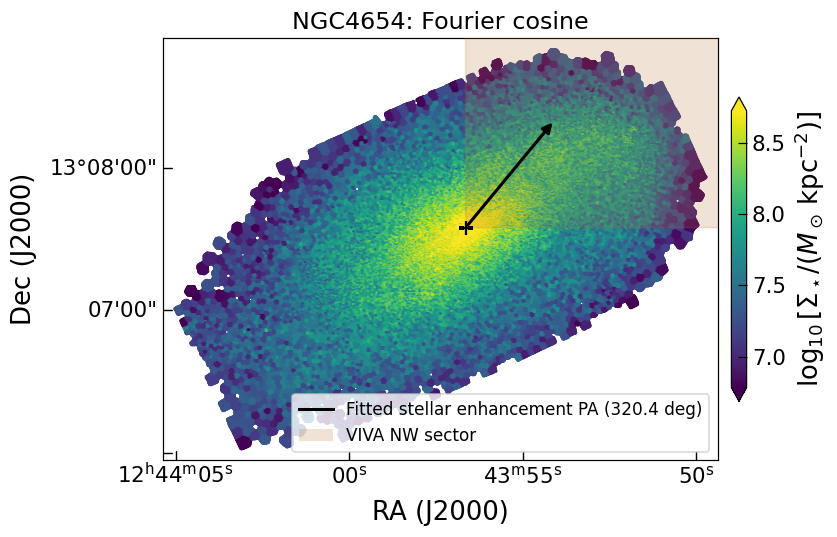

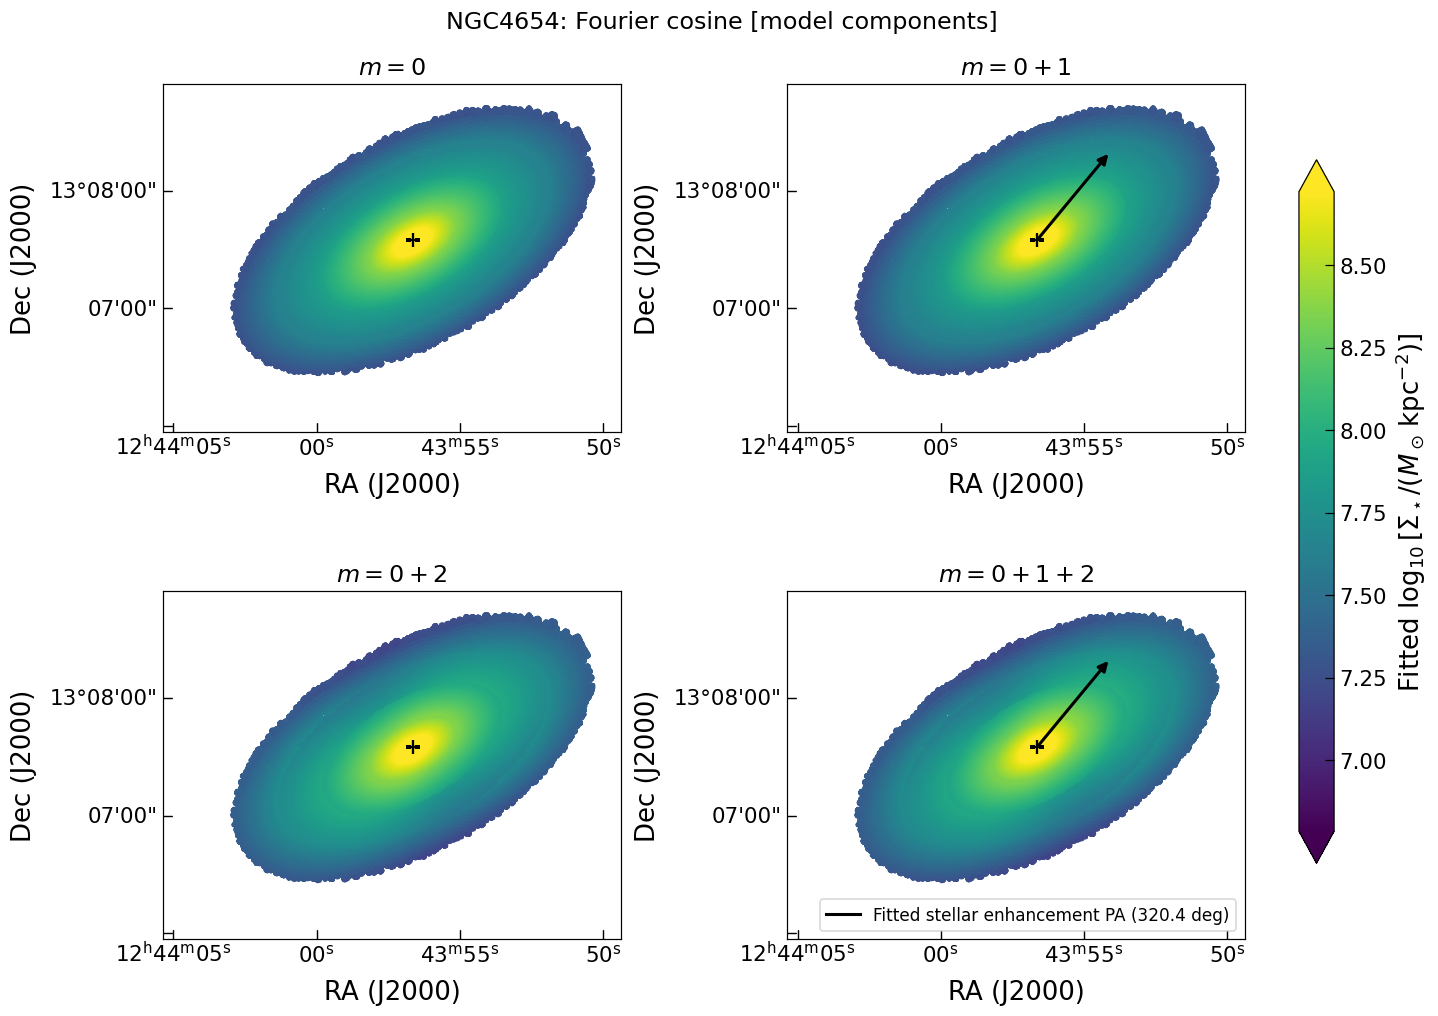

In [6]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# The plotted offsets are TAN plane coordinates in arcseconds.
ngc4654_centre = geometry_by_galaxy.loc['NGC4654']
ngc4654_sky_wcs = WCS(naxis=2)
ngc4654_sky_wcs.wcs.ctype = ['RA---TAN', 'DEC--TAN']
ngc4654_sky_wcs.wcs.crpix = [1, 1]  # Plot origin (0, 0) in zero-based coordinates.
ngc4654_sky_wcs.wcs.crval = [ngc4654_centre.center_ra_deg, ngc4654_centre.center_dec_deg]
ngc4654_sky_wcs.wcs.cdelt = [1 / 3600, 1 / 3600]
ngc4654_sky_wcs.wcs.radesys = 'FK5'
ngc4654_sky_wcs.wcs.equinox = 2000.0


def draw_ngc4654_arrow_map(ax_ngc4654, pa_deg, title, values, *,
                           cmap, vmin, vmax, show_legend=False, show_sector=True):
    east = ngc4654_map.east.to_numpy()
    north = ngc4654_map.north.to_numpy()
    shown = np.isfinite(values)
    mass_mesh = ax_ngc4654.scatter(east[shown], north[shown], c=values[shown],
        s=2, cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True, zorder=2)

    viva_color = '#b87333'
    if show_sector:
        # The VIVA overlay is the reference notebook's coarse NW compass sector.
        viva_pa_min, viva_pa_max = 270, 360
        viva_angles = np.deg2rad(np.linspace(viva_pa_min, viva_pa_max, 100))
        viva_radius = 1.2 * np.hypot(east, north).max()
        ax_ngc4654.fill(np.r_[0, viva_radius * np.sin(viva_angles), 0],
            np.r_[0, viva_radius * np.cos(viva_angles), 0],
            color=viva_color, alpha=0.20, zorder=3)

    if pa_deg is not None:
        muse_pa = np.deg2rad(pa_deg)
        arrow_length = 0.35 * min(np.ptp(east), np.ptp(north))
        ax_ngc4654.annotate('', xy=(arrow_length * np.sin(muse_pa), arrow_length * np.cos(muse_pa)),
            xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color='black', lw=2), zorder=5)
    ax_ngc4654.plot(0, 0, 'k+', ms=9, mew=1.5, zorder=4)
    ax_ngc4654.set(aspect='equal', xlim=(east.max() + 5, east.min() - 5),
        ylim=(north.min() - 5, north.max() + 5))
    ra_coord, dec_coord = ax_ngc4654.coords
    for coord, side, label, formatter in (
        (ra_coord, 'b', 'RA (J2000)', 'hh:mm:ss'),
        (dec_coord, 'l', 'Dec (J2000)', 'dd:mm:ss'),
    ):
        coord.set_ticks(number=4)
        coord.set_ticks_position(side)
        coord.set_ticklabel_position(side)
        coord.set_axislabel_position(side)
        coord.set_axislabel(label)
        coord.set_major_formatter(formatter)
        coord.set_ticklabel(exclude_overlapping=True)
    if show_legend:
        handles = [Line2D([], [], color='black', lw=2, label=f'Fitted stellar enhancement PA ({pa_deg:.1f} deg)')]
        if show_sector:
            handles.append(Patch(facecolor=viva_color, alpha=0.20, label='VIVA NW sector'))
        ax_ngc4654.legend(handles=handles, loc='lower right', fontsize=11)
    ax_ngc4654.set_title(title)
    return mass_mesh


def plot_ngc4654_arrow(pa_deg, title, diagnostics):
    fitted = diagnostics.set_index('binid', verify_integrity=True)
    radial, angular, total = (fitted[name] for name in ('radial', 'angular', 'fitted'))
    components = [
        (r'$m=0$', radial),
        (r'$m=0+1$', radial + angular),
        (r'$m=0+2$', total - angular),
        (r'$m=0+1+2$', total),
    ]
    if not np.isfinite(fitted[['radial', 'angular', 'fitted']].to_numpy()).all():
        raise ValueError('NGC4654: nonfinite fitted model component')
    if not ngc4654_map.binid.isin(fitted.index).any():
        raise ValueError('NGC4654: fitted bins do not overlap the map')

    projection = dict(projection=ngc4654_sky_wcs)
    cmap, vmin, vmax = 'viridis', MASS_VMIN, MASS_VMAX
    observed_fig, observed_ax = plt.subplots(figsize=(7.5, 5.25), layout='constrained',
        subplot_kw=projection)
    observed = draw_ngc4654_arrow_map(observed_ax, pa_deg, title,
        ngc4654_map.log_sigma_star.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmax, show_legend=True)
    observed_fig.colorbar(observed, ax=observed_ax, shrink=0.62, fraction=0.04, pad=0.025,
        extend='both', label=MASS_LABEL)
    plt.show()
    plt.close(observed_fig)

    grid, axes = plt.subplots(2, 2, figsize=(13, 9.5), layout='constrained', subplot_kw=projection)
    grid.suptitle(title + ' [model components]')
    for panel, (ax, (label_title, by_bin)) in enumerate(zip(axes.flat, components)):
        values = ngc4654_map.binid.map(by_bin).to_numpy()
        direction = pa_deg if panel in (1, 3) else None
        mesh = draw_ngc4654_arrow_map(ax, direction, label_title, values,
                                     cmap=cmap, vmin=vmin, vmax=vmax, show_legend=panel == 3, show_sector=False)
    grid.colorbar(mesh, ax=axes, shrink=0.75, extend='both', label='Fitted ' + MASS_LABEL)
    plt.show()
    plt.close(grid)


plot_ngc4654_arrow(ngc4654_fourier['PA_deg'], 'NGC4654: Fourier cosine',
                   ngc4654_cosine_diagnostics)


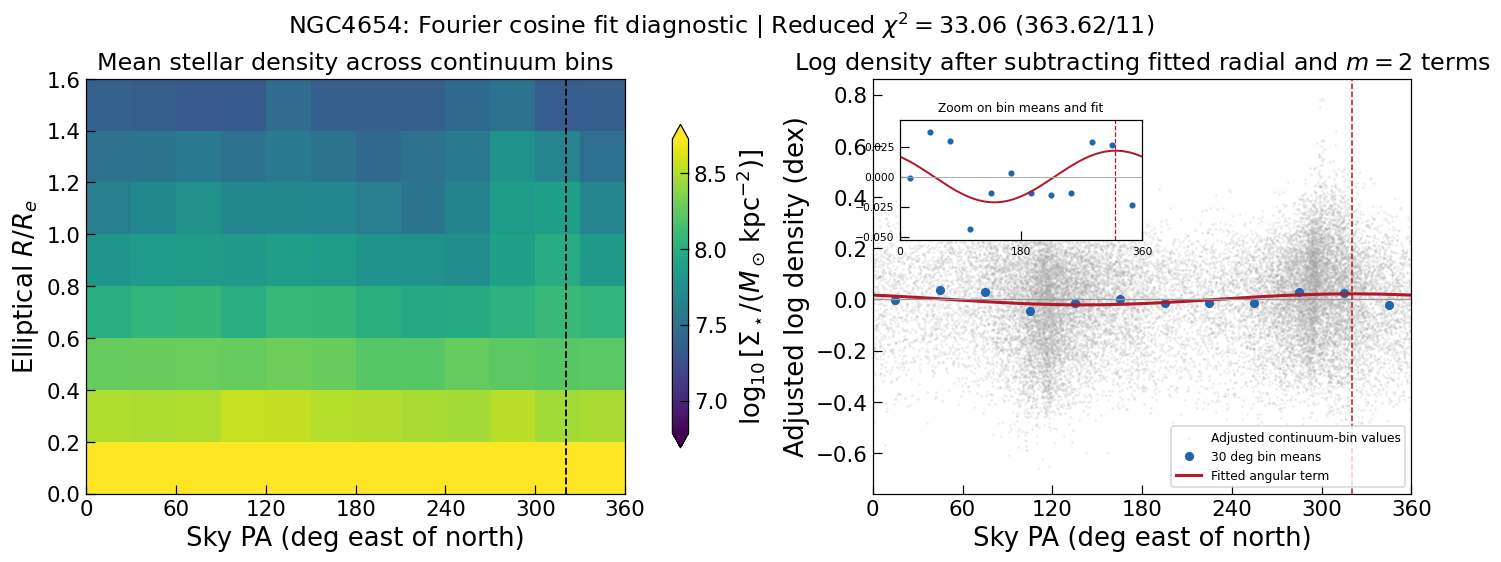

In [7]:
# Angular fit diagnostic adapted from cell 35 of the 20261015 NGC4654 notebook.
NGC4654_PA_EDGES = np.linspace(0, 360, 13)
# Two heatmap rows per fit annulus, retaining 0.2 Re visual bins.
NGC4654_RADIUS_EDGES = np.linspace(
    NGC4654_FIT_EDGES[0], NGC4654_FIT_EDGES[-1], 2 * (len(NGC4654_FIT_EDGES) - 1) + 1)


def ngc4654_mass_heatmap(frame):
    pa = np.rad2deg(frame.theta.to_numpy())
    radius = frame.r.to_numpy()
    grid = (NGC4654_PA_EDGES, NGC4654_RADIUS_EDGES)
    counts, _, _ = np.histogram2d(pa, radius, bins=grid)
    totals, _, _ = np.histogram2d(pa, radius, bins=grid, weights=frame.log_sigma_star.to_numpy())
    assert counts.sum() == len(frame)
    means = np.divide(totals, counts, out=np.full_like(totals, np.nan), where=counts > 0)
    return means, counts


def ngc4654_annular_design(theta, radius, annuli):
    """Annular terms in the order of the fitted coefficients."""
    edges = NGC4654_FIT_EDGES
    annulus = np.minimum(np.searchsorted(edges, radius, side='right') - 1, len(edges) - 2)
    cos2, sin2 = np.cos(2 * theta), np.sin(2 * theta)
    columns = []
    for a in annuli:
        member = annulus == a
        centre = (edges[a] + edges[a + 1]) / 2
        columns.extend([member, member * (radius - centre), member * cos2, member * sin2])
    return np.column_stack(columns)


def ngc4654_fit_jacobian(theta, radius, peak_pa, amplitude, kappa, annuli):
    """Local derivatives of the bin-fit prediction."""
    nuisance = ngc4654_annular_design(theta, radius, annuli)
    if kappa == 0:
        angular = [np.cos(theta), np.sin(theta)]
    else:
        offset = theta - peak_pa
        cosine = np.cos(offset)
        top = np.tanh(kappa * cosine)
        denominator = np.tanh(kappa)
        shape = top / denominator
        # Derivatives with respect to amplitude, phase (radians) and log(kappa).
        phase_slope = amplitude * kappa * (1 - top**2) * np.sin(offset) / denominator
        log_kappa_slope = amplitude * kappa * (
            cosine * (1 - top**2) - shape * (1 - denominator**2)) / denominator
        angular = [shape, phase_slope, log_kappa_slope]
    return np.column_stack([nuisance, *angular])


def ngc4654_angular_reduced_chi2(frame, pa_deg, amplitude, kappa, *, localized_shape=None, localized_width_slope=None):
    # The bin-average adjusted log density minus the bin-average fitted angular term
    # is exactly the bin-average residual of the full model.
    theta = frame.theta.to_numpy()
    residual = (frame.log_sigma_star - frame.fitted).to_numpy()
    edges = NGC4654_PA_EDGES
    sector = np.minimum(np.searchsorted(edges, np.rad2deg(theta), side='right') - 1,
                        len(edges) - 2)
    n_sectors = len(edges) - 1
    sector_count = np.bincount(sector, minlength=n_sectors)
    populated = sector_count > 0

    def sector_mean(values):
        return np.bincount(sector, weights=values, minlength=n_sectors)[populated] / sector_count[populated]

    # One residual per continuum bin. Project each bin's contribution through
    # the fit so the covariance accounts for estimating the model coefficients.
    assert frame.binid.is_unique
    fit_edges = NGC4654_FIT_EDGES
    radius = frame.r.to_numpy()
    annuli = np.unique(np.minimum(
        np.searchsorted(fit_edges, radius, side='right') - 1, len(fit_edges) - 2))
    if localized_shape is None:
        jacobian = ngc4654_fit_jacobian(theta, radius, np.deg2rad(pa_deg),
                                       amplitude, kappa, annuli)
    else:
        offset = theta - np.deg2rad(pa_deg)
        step = 1e-5  # radians; fixed width/kappa, differentiate only the fitted PA
        phase_slope = amplitude * (localized_shape(offset - step)
                                   - localized_shape(offset + step)) / (2 * step)
        columns = [ngc4654_annular_design(theta, radius, annuli),
                   localized_shape(offset), phase_slope]
        if localized_width_slope is not None:
            columns.append(amplitude * localized_width_slope(offset))
        jacobian = np.column_stack(columns)
    q, r = np.linalg.qr(jacobian, mode='reduced')
    if np.linalg.matrix_rank(r) != r.shape[1]:
        raise ValueError('Rank-deficient fit Jacobian for angular chi-square')
    direct = (np.flatnonzero(populated)[:, None] == sector) * residual
    direct /= sector_count[populated, None]
    mean_q = np.column_stack([sector_mean(column) for column in q.T])
    influences = direct - np.einsum('ij,jg->ig', mean_q, q.T * residual)
    bin_residuals = sector_mean(residual)
    if kappa == 0 and localized_shape is None:
        np.testing.assert_allclose(influences.sum(axis=1), bin_residuals, atol=1e-10)

    covariance = np.einsum('ig,jg->ij', influences, influences)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    keep = eigenvalues > eigenvalues.max() * 1e-10
    covariance_rank = int(keep.sum())
    if covariance_rank == 0:
        raise ValueError('Angular residual covariance has zero rank')
    standardized = np.einsum('ij,i->j', eigenvectors[:, keep], bin_residuals) / np.sqrt(eigenvalues[keep])
    chi2 = np.sum(standardized**2)
    return dict(chi2=chi2, covariance_rank=covariance_rank, reduced_chi2=chi2 / covariance_rank)


def plot_ngc4654_angular_diagnostic(frame, pa_deg, amplitude, kappa, title, *, localized_shape=None, localized_width_slope=None):
    assert frame.binid.is_unique
    pa_edges, radius_edges = NGC4654_PA_EDGES, NGC4654_RADIUS_EDGES
    pa = np.rad2deg(frame.theta.to_numpy())
    observed = frame.log_sigma_star.to_numpy()
    angular = frame.angular.to_numpy()
    fitted = frame.fitted.to_numpy()
    adjusted = observed - (fitted - angular)
    np.testing.assert_allclose(adjusted - angular, observed - fitted, atol=1e-12)

    mean_2d, _ = ngc4654_mass_heatmap(frame)
    count_1d = np.histogram(pa, bins=pa_edges)[0]
    total_1d = np.histogram(pa, bins=pa_edges, weights=adjusted)[0]
    means = np.divide(total_1d, count_1d, out=np.full_like(total_1d, np.nan),
                      where=count_1d > 0)
    centres = (pa_edges[:-1] + pa_edges[1:]) / 2

    grid = np.linspace(0, 360, 721)
    cosine = np.cos(np.deg2rad(grid - pa_deg))
    if localized_shape is None:
        curve = amplitude * (np.tanh(kappa * cosine) / np.tanh(kappa) if kappa > 0 else cosine)
    else:
        curve = amplitude * localized_shape(np.deg2rad(grid - pa_deg))
    fig, (ax_radial, ax_angular) = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
    mesh = ax_radial.pcolormesh(pa_edges, radius_edges, mean_2d.T, cmap='viridis',
                               vmin=MASS_VMIN, vmax=MASS_VMAX, shading='flat')
    ax_radial.axvline(pa_deg, color='black', ls='--', lw=1.2)
    ax_radial.set(xlim=(0, 360), ylim=(radius_edges[0], radius_edges[-1]), xticks=np.arange(0, 361, 60),
                  xlabel='Sky PA (deg east of north)', ylabel=r'Elliptical $R/R_e$',
                  title='Mean stellar density across continuum bins')
    fig.colorbar(mesh, ax=ax_radial, shrink=0.78, extend='both', label=MASS_LABEL)

    ax_angular.scatter(pa, adjusted, s=1, color='0.65', alpha=0.12, rasterized=True,
                       label='Adjusted continuum-bin values')
    ax_angular.plot(centres, means, 'o', ms=5, color='#2166ac',
                    label='30 deg bin means')
    if localized_shape is not None:
        # Average the model over the actual sampled PAs in each bin.
        total_model = np.histogram(pa, bins=pa_edges, weights=angular)[0]
        model_means = np.divide(total_model, count_1d, out=np.full_like(total_model, np.nan),
                                where=count_1d > 0)
        ax_angular.plot(centres, model_means, 'x', ms=5, color='#b2182b',
                        label='Fit averaged in 30 deg bins')
    ax_angular.plot(grid, curve, color='#b2182b', lw=2, label='Fitted angular term')
    ax_angular.axhline(0, color='0.6', lw=0.8)
    ax_angular.axvline(pa_deg, color='#b2182b', ls='--', lw=1)
    ax_angular.set(xlim=(0, 360), xticks=np.arange(0, 361, 60),
                   xlabel='Sky PA (deg east of north)', ylabel='Adjusted log density (dex)',
                   title=r'Log density after subtracting fitted radial and $m=2$ terms')
    ax_angular.legend(fontsize=8, loc='lower right')

    inset = ax_angular.inset_axes([0.05, 0.61, 0.45, 0.29])
    inset.plot(centres, means, 'o', ms=3, color='#2166ac')
    if localized_shape is not None:
        inset.plot(centres, model_means, 'x', ms=3, color='#b2182b')
    inset.plot(grid, curve, color='#b2182b', lw=1.3)
    inset.axhline(0, color='0.65', lw=0.6)
    inset.axvline(pa_deg, color='#b2182b', ls='--', lw=0.8)
    lo, hi = np.nanmin(np.r_[means, curve]), np.nanmax(np.r_[means, curve])
    pad = 0.12 * max(hi - lo, 1e-6)
    inset.set(xlim=(0, 360), ylim=(lo - pad, hi + pad), xticks=[0, 180, 360],
              title='Zoom on bin means and fit')
    inset.title.set_fontsize(8)
    inset.tick_params(labelsize=7)
    chi2_summary = ngc4654_angular_reduced_chi2(
        frame, pa_deg, amplitude, kappa, localized_shape=localized_shape,
        localized_width_slope=localized_width_slope)
    chi2 = chi2_summary['chi2']
    dof = chi2_summary['covariance_rank']
    reduced = chi2_summary['reduced_chi2']
    fig.suptitle(title + fr' | Reduced $\chi^2={reduced:.2f}$ ({chi2:.2f}/{dof})')
    plt.show()
    plt.close(fig)
    return chi2_summary


ngc4654_cosine_chi2 = plot_ngc4654_angular_diagnostic(
    ngc4654_cosine_diagnostics, ngc4654_fourier['PA_deg'],
    ngc4654_fourier['amplitude_dex'],
    0.0, 'NGC4654: Fourier cosine fit diagnostic')


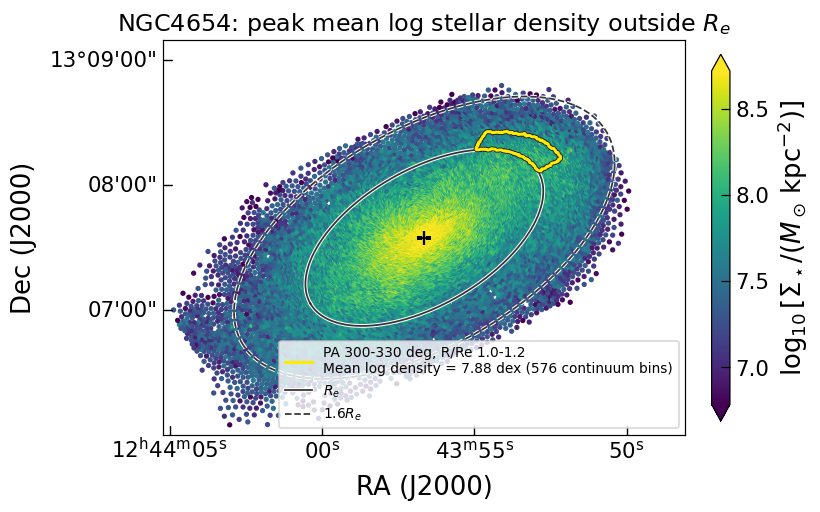

In [8]:
# Locate the highest mean of continuum-bin log densities outside Re.
from matplotlib import patheffects

fit_bins = ngc4654_cosine_diagnostics
heatmap_means, heatmap_counts = ngc4654_mass_heatmap(fit_bins)
outer_rows = NGC4654_RADIUS_EDGES[:-1] >= 1.0
outer_heatmap_means = np.where(outer_rows[None, :], heatmap_means, np.nan)
if not np.isfinite(outer_heatmap_means).any():
    raise ValueError('No populated continuum-bin sectors outside Re.')
peak_pa_bin, peak_r_bin = np.unravel_index(
    np.nanargmax(outer_heatmap_means), outer_heatmap_means.shape)
peak_pa_bounds = NGC4654_PA_EDGES[peak_pa_bin:peak_pa_bin + 2]
peak_r_bounds = NGC4654_RADIUS_EDGES[peak_r_bin:peak_r_bin + 2]
peak_mean_log_sigma_star = heatmap_means[peak_pa_bin, peak_r_bin]

# Match histogram2d: lower edges inclusive, upper edges exclusive except at the end.
fit_pa = np.rad2deg(fit_bins.theta.to_numpy())
fit_r = fit_bins.r.to_numpy()
pa_index = np.minimum(np.searchsorted(NGC4654_PA_EDGES, fit_pa, side='right') - 1,
                      len(NGC4654_PA_EDGES) - 2)
r_index = np.minimum(np.searchsorted(NGC4654_RADIUS_EDGES, fit_r, side='right') - 1,
                     len(NGC4654_RADIUS_EDGES) - 2)
peak_bins = fit_bins.loc[(pa_index == peak_pa_bin) & (r_index == peak_r_bin)]
assert len(peak_bins) == heatmap_counts[peak_pa_bin, peak_r_bin]
np.testing.assert_allclose(peak_bins.log_sigma_star.mean(), peak_mean_log_sigma_star)

# Outline every native pixel of each selected continuum BINID.
peak_y, peak_x = np.nonzero(np.isin(ngc4654_native_binid, peak_bins.binid.to_numpy()))
# Include a one-pixel border so the contour closes at the edge of the data.
contour_x = np.arange(peak_x.min() - 1, peak_x.max() + 2)
contour_y = np.arange(peak_y.min() - 1, peak_y.max() + 2)
peak_mask = np.zeros((len(contour_y), len(contour_x)), dtype=bool)
peak_mask[peak_y - contour_y[0], peak_x - contour_x[0]] = True

fig_corner, ax_corner = plt.subplots(
    figsize=(7.5, 5.25), layout='constrained', subplot_kw={'projection': ngc4654_sky_wcs})
map_east = ngc4654_bins.east.to_numpy()
map_north = ngc4654_bins.north.to_numpy()
peak_mesh = ax_corner.scatter(
    map_east, map_north, c=ngc4654_bins.log_sigma_star, cmap='viridis',
    vmin=MASS_VMIN, vmax=MASS_VMAX, s=6, rasterized=True)
peak_outline = ax_corner.contour(
    contour_x, contour_y, peak_mask.astype(float), levels=[0.5],
    transform=ax_corner.get_transform(native_wcs),
    colors=['#ffeb00'], linewidths=1.8, zorder=5)
peak_outline.set_path_effects([patheffects.Stroke(linewidth=3.0, foreground='0.15'),
                                patheffects.Normal()])
ax_corner.plot(0, 0, 'k+', ms=9, mew=1.5)
# Invert the same major/minor-axis rotation used for the heatmap radius.
ellipse_angle = np.linspace(0, 2 * np.pi, 361)
major_pa = np.deg2rad(ngc4654_centre.pa_deg_east_of_north)
major = ngc4654_centre.a_re_arcsec * np.cos(ellipse_angle)
minor = ngc4654_centre.b_re_arcsec * np.sin(ellipse_angle)
re_east = major * np.sin(major_pa) + minor * np.cos(major_pa)
re_north = major * np.cos(major_pa) - minor * np.sin(major_pa)
radius_lines = []
fit_outer_radius = NGC4654_FIT_EDGES[-1]
for scale, linestyle, radius_label in [(1, '-', r'$R_e$'),
                                       (fit_outer_radius, '--', fr'{fit_outer_radius:g}$R_e$')]:
    line, = ax_corner.plot(scale * re_east, scale * re_north, color='0.2',
                           ls=linestyle, lw=1.15, label=radius_label, zorder=4)
    line.set_path_effects([patheffects.Stroke(linewidth=2.5, foreground='white'),
                           patheffects.Normal()])
    radius_lines.append(line)
east_limit = max(np.abs(map_east).max(), fit_outer_radius * np.abs(re_east).max()) + 5
north_limit = max(np.abs(map_north).max(), fit_outer_radius * np.abs(re_north).max()) + 5
ax_corner.set(title=r'NGC4654: peak mean log stellar density outside $R_e$', aspect='equal',
              xlim=(east_limit, -east_limit), ylim=(-north_limit, north_limit))
for coord, side, label, formatter in (
    (ax_corner.coords[0], 'b', 'RA (J2000)', 'hh:mm:ss'),
    (ax_corner.coords[1], 'l', 'Dec (J2000)', 'dd:mm:ss'),
):
    coord.set_ticks(number=4)
    coord.set_ticks_position(side)
    coord.set_ticklabel_position(side)
    coord.set_major_formatter(formatter)
    coord.set_ticklabel(exclude_overlapping=True)
    coord.set_axislabel(label)
pa_lo, pa_hi = peak_pa_bounds
r_lo, r_hi = peak_r_bounds
label = (f'PA {pa_lo:.0f}-{pa_hi:.0f} deg, R/Re {r_lo:.1f}-{r_hi:.1f}'
         f'\nMean log density = {peak_mean_log_sigma_star:.2f} dex ({len(peak_bins)} continuum bins)')
ax_corner.legend(handles=[Line2D([], [], color='#ffeb00', lw=2, label=label),
                          *radius_lines],
                 loc='lower right', fontsize=9)
fig_corner.colorbar(peak_mesh, ax=ax_corner, shrink=0.73, extend='both', label=MASS_LABEL)
plt.show()
plt.close(fig_corner)


## Fourier cosine fit with four annular amplitudes

$$
\begin{aligned}
\widehat y_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A_a\cos(\phi_i-\theta)}_{m=1}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

Use the same four annuli, continuum bins, and annular intercepts, radial slopes and \(m=2\) terms as the original Fourier fit. Replace its shared amplitude with \(A_a\cos(\phi-\theta)\), where each annulus has its own \(A_a\geq0\) and all four share one sky PA \(\theta\). The nonnegative constraint gives the amplitudes a common enhancement direction and lets an annulus have zero modulation. At each trial PA, solve for the annular amplitudes and nuisance terms, then minimize the total residual sum of squares over PA.

The shared-amplitude fit is a special case of this model. Compare RSS, RMSE, and \(R^2\) on the identical bins to see how much the three extra amplitude parameters improve the in-sample fit. The annular panel shows means in 30° PA bins after subtracting the nuisance terms of the new fit.

In [9]:
def fit_ngc4654_annular_amplitudes(frame):
    """Fit a shared Fourier phase and one nonnegative amplitude per annulus."""
    from scipy.optimize import minimize_scalar

    assert frame.binid.is_unique
    theta, radius, y = (frame[col].to_numpy(float) for col in ('theta', 'r', 'log_sigma_star'))
    edges = NGC4654_FIT_EDGES
    annuli = np.arange(len(edges) - 1)
    annulus = np.minimum(np.searchsorted(edges, radius, side='right') - 1, annuli[-1])
    if not np.array_equal(np.unique(annulus), annuli):
        raise ValueError('All four Fourier annuli must be populated')
    design = ngc4654_annular_design(theta, radius, annuli)
    q, r = np.linalg.qr(design, mode='reduced')
    if np.linalg.cond(r) > 1e6:
        raise ValueError('Poorly conditioned annular design')

    def residualize(values):
        return values - np.einsum('ij,j...->i...', q, np.einsum('ij,i...->j...', q, values))

    y0 = residualize(y)
    basis = np.column_stack([np.cos(theta), np.sin(theta)])
    basis0 = residualize(basis)
    # The nuisance design is block diagonal by annulus. Its residualized
    # cosine and sine columns give the linear fit for any shared phase.
    gram = np.stack([np.einsum('ni,nj->ij', basis0[annulus == a], basis0[annulus == a])
                     for a in annuli])
    score = np.stack([np.einsum('ni,n->i', basis0[annulus == a], y0[annulus == a])
                      for a in annuli])
    if np.any(np.linalg.eigvalsh(gram)[:, 0] <= 0):
        raise ValueError('An annulus cannot identify the Fourier amplitude')

    def profile(pa):
        direction = np.array([np.cos(pa), np.sin(pa)])
        numerator = np.maximum(0.0, np.einsum('ai,i->a', score, direction))
        denominator = np.einsum('i,aij,j->a', direction, gram, direction)
        amplitude = numerator / denominator
        return np.sum(numerator * amplitude), amplitude

    # Evaluate the full circle and refine each candidate peak continuously,
    # including peaks at the 0/360 seam.
    grid = np.deg2rad(np.arange(360.0))
    gains = np.array([profile(pa)[0] for pa in grid])
    peaks = np.flatnonzero((gains > 0) & (gains >= np.roll(gains, 1))
                          & (gains >= np.roll(gains, -1)))
    if peaks.size == 0:
        raise ValueError('No identifiable shared Fourier phase')
    step = grid[1]
    fits = [minimize_scalar(lambda pa: -profile(pa)[0], method='bounded',
                            bounds=(grid[i] - step, grid[i] + step),
                            options={'xatol': 1e-12}) for i in peaks]
    if not all(fit.success for fit in fits):
        raise RuntimeError('Annular Fourier phase refinement failed')
    pa = min(fits, key=lambda fit: fit.fun).x % (2 * np.pi)
    gain, amplitude = profile(pa)
    angular = amplitude[annulus] * np.cos(theta - pa)
    nuisance_coeff = np.linalg.solve(r, np.einsum('ij,i->j', q, y - angular))
    prediction = np.einsum('ij,j->i', design, nuisance_coeff) + angular
    np.testing.assert_allclose(np.sum(y0**2) - np.sum((y - prediction)**2), gain,
                               rtol=1e-9, atol=1e-10)
    return np.rad2deg(pa) % 360, amplitude, frame.assign(
        annulus=annulus, fitted=prediction, angular=angular,
        radial=annular_radial_term(design, nuisance_coeff))

,PA_deg,N_BINID,RSS,RMSE_dex,R2,RSS_reduction_pct
model,,,,,,
Shared amplitude,320.409246,22801,711.618070,0.176663,0.847486,0.0000
Four annular amplitudes,310.844698,22801,698.917113,0.175080,0.850208,1.7848


,N_BINID,shared_amplitude_dex,free_amplitude_dex,shared_RMSE_dex,free_RMSE_dex
annulus,,,,,
0.0-0.4 Re,6803,0.0215,0.008436,0.159668,0.159253
0.4-0.8 Re,7377,0.0215,0.000000,0.173001,0.171393
0.8-1.2 Re,5369,0.0215,0.056843,0.187619,0.185283
1.2-1.6 Re,3252,0.0215,0.056677,0.198705,0.196341


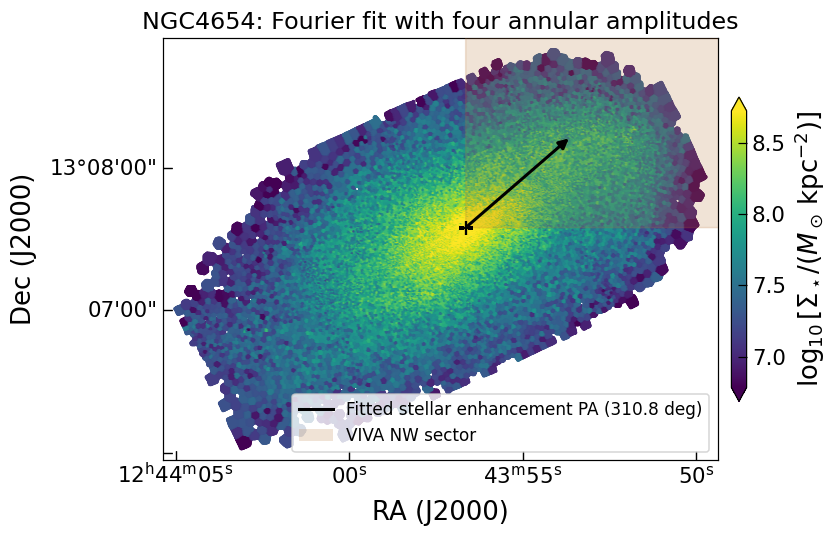

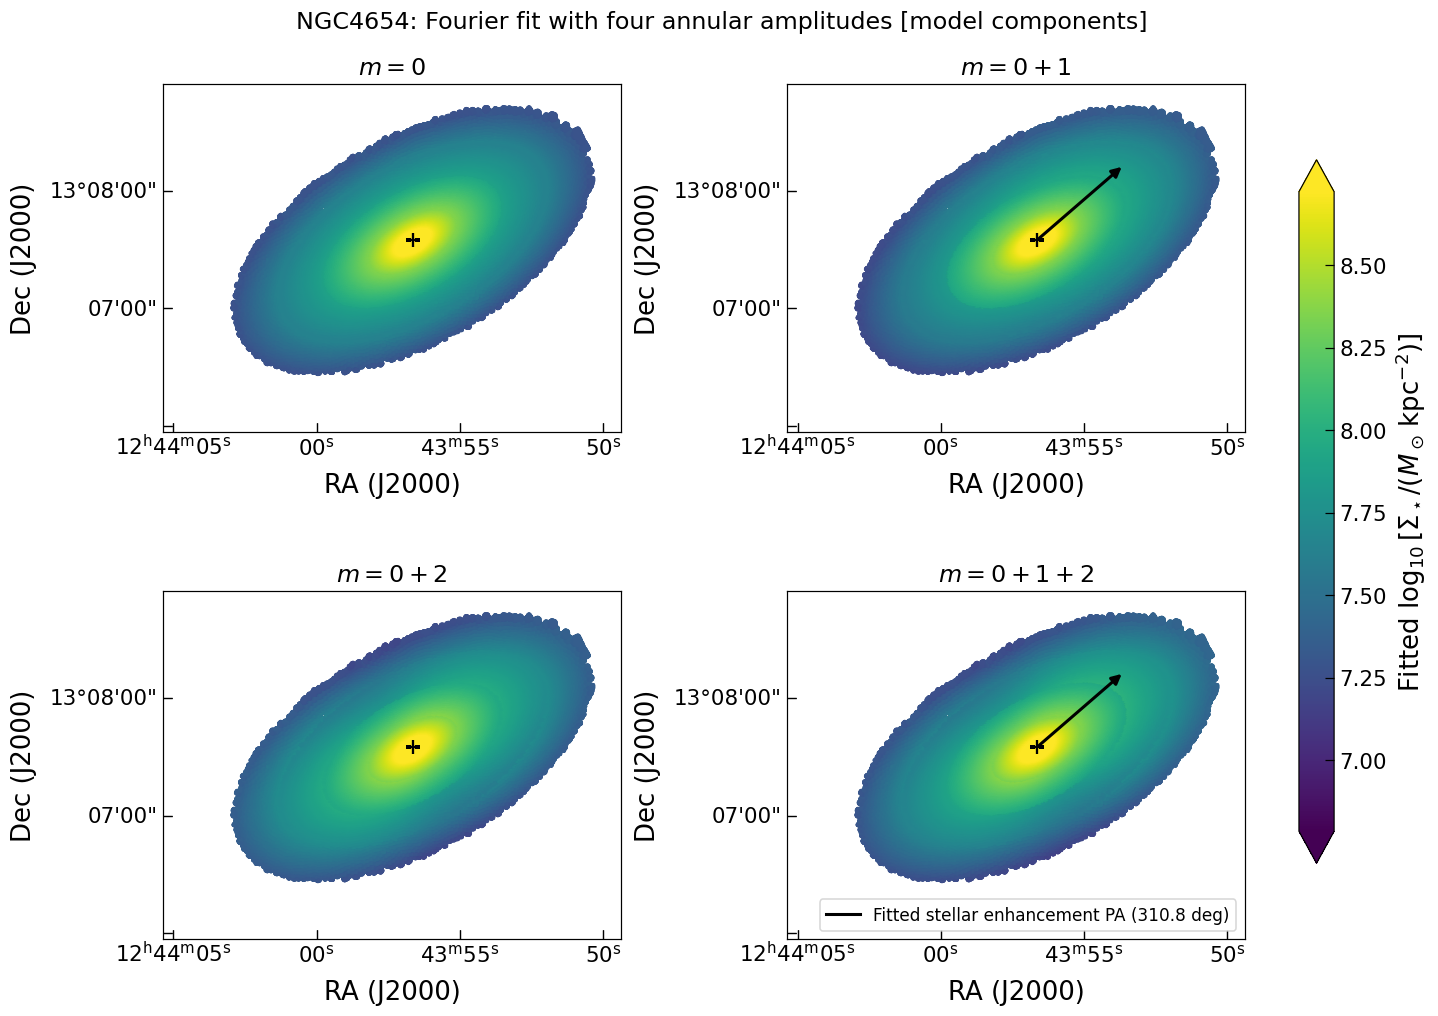

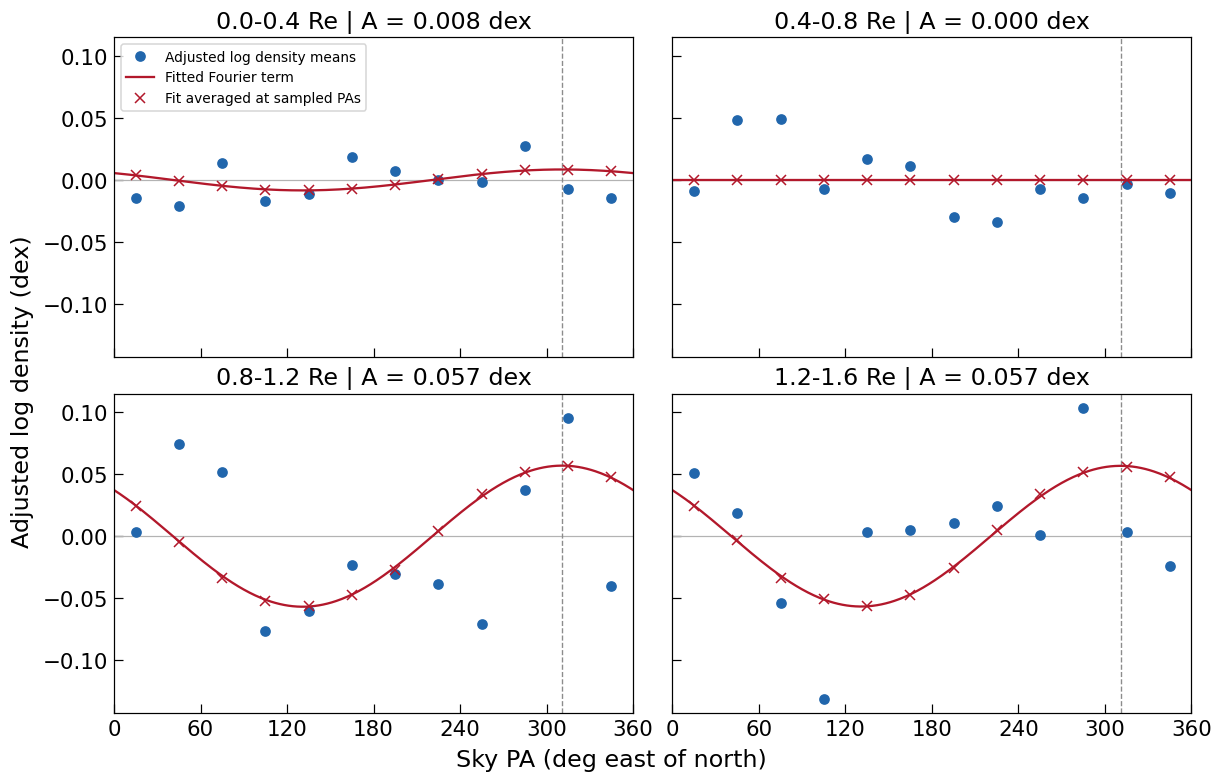

In [10]:
ngc4654_annular_pa, ngc4654_annular_amplitudes, ngc4654_annular_diagnostics = (
    fit_ngc4654_annular_amplitudes(ngc4654_cosine_diagnostics))
original = ngc4654_cosine_diagnostics
annular_fit = ngc4654_annular_diagnostics
assert annular_fit[['theta', 'r', 'binid', 'log_sigma_star']].equals(original[['theta', 'r', 'binid', 'log_sigma_star']])
observed = original.log_sigma_star.to_numpy()
comparison_rows = []
for model, pa, fitted in (
    ('Shared amplitude', ngc4654_fourier['PA_deg'], original.fitted),
    ('Four annular amplitudes', ngc4654_annular_pa, annular_fit.fitted),
):
    rss = np.sum((observed - fitted.to_numpy())**2)
    comparison_rows.append(dict(model=model, PA_deg=pa, N_BINID=len(observed), RSS=rss,
                                RMSE_dex=np.sqrt(rss / len(observed)),
                                R2=1 - rss / np.sum((observed - observed.mean())**2)))
ngc4654_annular_comparison = pd.DataFrame(comparison_rows).set_index('model')
shared_rss = ngc4654_annular_comparison.loc['Shared amplitude', 'RSS']
assert ngc4654_annular_comparison.loc['Four annular amplitudes', 'RSS'] <= shared_rss + 1e-8
ngc4654_annular_comparison['RSS_reduction_pct'] = 100 * (
    1 - ngc4654_annular_comparison.RSS / shared_rss)
display(ngc4654_annular_comparison.round(6))

annular_rows = []
for a, amplitude in enumerate(ngc4654_annular_amplitudes):
    take = annular_fit.annulus.eq(a)
    residuals_shared = original.log_sigma_star[take] - original.fitted[take]
    residuals_free = annular_fit.log_sigma_star[take] - annular_fit.fitted[take]
    annular_rows.append(dict(
        annulus=f'{NGC4654_FIT_EDGES[a]:.1f}-{NGC4654_FIT_EDGES[a+1]:.1f} Re',
        N_BINID=int(take.sum()), shared_amplitude_dex=ngc4654_fourier['amplitude_dex'],
        free_amplitude_dex=amplitude,
        shared_RMSE_dex=np.sqrt(np.mean(residuals_shared**2)),
        free_RMSE_dex=np.sqrt(np.mean(residuals_free**2))))
ngc4654_annular_summary = pd.DataFrame(annular_rows).set_index('annulus')
display(ngc4654_annular_summary.round(6))

plot_ngc4654_arrow(ngc4654_annular_pa, 'NGC4654: Fourier fit with four annular amplitudes',
                   ngc4654_annular_diagnostics)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True, layout='constrained')
pa_edges = NGC4654_PA_EDGES
pa_centres = (pa_edges[1:] + pa_edges[:-1]) / 2
pa_grid = np.linspace(0, 360, 361)
for a, ax in enumerate(axes.flat):
    ann = annular_fit.loc[annular_fit.annulus.eq(a)]
    pa = np.rad2deg(ann.theta.to_numpy())
    adjusted = (ann.log_sigma_star - (ann.fitted - ann.angular)).to_numpy()
    counts = np.histogram(pa, bins=pa_edges)[0]

    def bin_means(values):
        totals = np.histogram(pa, bins=pa_edges, weights=values)[0]
        return np.divide(totals, counts, out=np.full_like(totals, np.nan), where=counts > 0)

    amplitude = ngc4654_annular_amplitudes[a]
    ax.axhline(0, color='0.7', lw=0.8)
    ax.axvline(ngc4654_annular_pa, color='0.55', ls='--', lw=0.9)
    ax.plot(pa_centres, bin_means(adjusted), 'o', color='#2166ac', label='Adjusted log density means')
    ax.plot(pa_grid, amplitude * np.cos(np.deg2rad(pa_grid - ngc4654_annular_pa)),
            color='#b2182b', label='Fitted Fourier term')
    ax.plot(pa_centres, bin_means(ann.angular.to_numpy()), 'x', color='#b2182b',
            label='Fit averaged at sampled PAs')
    ax.set(xlim=(0, 360), xticks=np.arange(0, 361, 60),
           title=f'{ngc4654_annular_summary.index[a]} | A = {amplitude:.3f} dex')
axes[0, 0].legend(fontsize=9, loc='best')
fig.supxlabel('Sky PA (deg east of north)')
fig.supylabel('Adjusted log density (dex)')
plt.show()
plt.close(fig)

## Smooth opposite-half fit

$$
\begin{aligned}
\widehat y_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{\tanh[\kappa\cos(\phi_i-\theta)]}{\tanh\kappa}}_{\text{opposite-half term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

Fit the shared angular term with \(A\tanh[\kappa\cos(\phi-\theta)]/\tanh\kappa\), following the shape proposed in [Fourier Approach Assessment](https://chatgpt.com/c/6afba860-2ac0-83ec-8ae5-877d28f9c267). The transition sharpness \(\kappa\) and sky PA \(\theta\), east of north, are fitted jointly. The amplitude \(A\geq0\) is the peak angular amplitude in dex, so the contrast between opposite central directions is \(2A\). For \(\kappa>0\), this parameterization has \(\gamma=A/\tanh\kappa\) in the original formula. Its \(\kappa=0\) limit is the Fourier cosine.

Use the same continuum bins with centroids within \(1.6R_e\) and four annular nuisance terms per populated annulus (intercept, radial slope, and the \(m=2\) cosine/sine pair). Give each continuum bin equal weight and refit the nuisance coefficients for each model. Compare in-sample \(R^2\) and RMSE on the same footprint. The table reports point estimates for this alternative, and the diagnostic below compares the fitted angular curve with log stellar density after subtracting the fitted annular terms.

The angular diagnostics report generalized reduced \(\chi^2\), using the rank of the covariance of the 30 deg bin residual means as the denominator. Each fitted BINID contributes one residual, and the covariance accounts for estimating the model from those same bin means. The positive-\(\kappa\) covariance uses local fit derivatives. At \(\kappa=0\), the diagnostic uses the cosine limit. The statistic describes fit adequacy on this footprint.

In [11]:
from scipy.optimize import minimize


def compare_ngc4654_angular_models(frame):
    edges = NGC4654_FIT_EDGES
    theta = np.arctan2(frame.east.to_numpy(), frame.north.to_numpy()) % (2 * np.pi)
    radius = frame.r.to_numpy()
    binid = frame.binid.to_numpy()
    log_sigma_star = frame.log_sigma_star.to_numpy()
    keep = (np.isfinite(binid) & (binid >= 0) & (binid == np.floor(binid))
            & (np.hypot(frame.east.to_numpy(), frame.north.to_numpy()) > 0)
            & np.isfinite(theta) & (radius >= edges[0]) & (radius <= edges[-1])
            & np.isfinite(log_sigma_star))
    theta, radius, y = theta[keep], radius[keep], log_sigma_star[keep]
    bins = np.unique(binid[keep].astype(np.int64))
    annulus = np.minimum(np.searchsorted(edges, radius, side='right') - 1, len(edges) - 2)
    columns = []
    for a in np.unique(annulus):
        member = annulus == a
        center = (edges[a] + edges[a + 1]) / 2
        columns.extend([member, member * (radius - center),
                        member * np.cos(2 * theta), member * np.sin(2 * theta)])
    nuisance = np.column_stack(columns)
    q, r = np.linalg.qr(nuisance, mode='reduced')
    if np.linalg.cond(r) > 1e6:
        raise ValueError('Poorly conditioned annular design')
    nuisance_score = np.einsum('ij,i->j', q, y)
    residual_y = y - np.einsum('ij,j->i', q, nuisance_score)
    cos_theta, sin_theta = np.cos(theta), np.sin(theta)

    def half_column(pa, kappa):
        cosine = cos_theta * np.cos(pa) + sin_theta * np.sin(pa)
        # Unit peak keeps amplitude well defined through the cosine limit.
        return np.tanh(kappa * cosine) / np.tanh(kappa) if kappa > 0 else cosine

    def profile(pa, kappa):
        # Solve the linear amplitude and nuisance terms at each trial PA and kappa.
        column = half_column(pa, kappa)
        projection = np.einsum('ij,i->j', q, column)
        norm2 = np.dot(column, column) - np.dot(projection, projection)
        if norm2 <= 0:
            raise ValueError('Half template is degenerate with the annular terms')
        score = max(0.0, np.dot(column, residual_y))
        return score**2 / norm2, score / norm2, projection

    period = 2 * np.pi

    cosine_design = np.column_stack([nuisance, cos_theta, sin_theta])
    cosine_coeff, _, rank, _ = np.linalg.lstsq(
        cosine_design, y, rcond=None)
    if rank != cosine_design.shape[1]:
        raise ValueError('Rank-deficient cosine design')
    cosine_prediction = np.einsum('ij,j->i', cosine_design, cosine_coeff)
    c1, s1 = cosine_coeff[-2:]
    cosine_amp = np.hypot(c1, s1)
    cosine_pa = np.arctan2(s1, c1) % period
    # Seed the continuous search over PA and log(kappa) on a periodic PA grid.
    # The exact kappa=0 limit is supplied by the independent cosine fit.
    pa_grid = np.linspace(0.0, period, 72, endpoint=False)
    pa_step = pa_grid[1]
    log_kappa_grid = np.log([0.01, 0.05, 0.125, 0.25, 0.5, 1, 2, 4, 8,
                             16, 32, 64, 128, 512, 2048, 8192, 32768])
    gains = np.array([[profile(pa, np.exp(log_kappa))[0] for pa in pa_grid]
                      for log_kappa in log_kappa_grid])
    pa_peaks = (gains >= np.roll(gains, 1, axis=1)) & (gains >= np.roll(gains, -1, axis=1))
    kappa_peaks = ((gains >= np.vstack([gains[:1], gains[:-1]]))
                   & (gains >= np.vstack([gains[1:], gains[-1:]])))
    peaks = np.argwhere((gains > 0) & pa_peaks & kappa_peaks)
    solutions = []
    for k, p in peaks:
        pa = pa_grid[p]
        bounds = [(pa - pa_step, pa + pa_step),
                  (log_kappa_grid[max(0, k - 1)], log_kappa_grid[min(k + 1, len(log_kappa_grid) - 1)])]
        fit = minimize(lambda trial: -profile(trial[0], np.exp(trial[1]))[0],
                       x0=[pa, log_kappa_grid[k]], bounds=bounds, method='L-BFGS-B',
                       options={'ftol': 1e-12, 'gtol': 1e-5})
        if not fit.success:
            raise RuntimeError(f'Opposite-half fit did not converge: {fit.message}')
        solutions.append(fit)
    best = min(solutions, key=lambda fit: fit.fun)
    half_pa, log_kappa = best.x
    kappa = np.exp(log_kappa)
    cosine_gain = np.dot(residual_y, residual_y) - np.sum((y - cosine_prediction)**2)
    if -best.fun <= cosine_gain + 1e-8:
        half_pa, kappa = cosine_pa, 0.0
    elif np.isclose(log_kappa, log_kappa_grid[0]) or np.isclose(log_kappa, log_kappa_grid[-1]):
        raise RuntimeError('Opposite-half sharpness reached a numerical search limit')
    half_gain, half_peak, projection = profile(half_pa, kappa)
    half_baseline = np.linalg.solve(r, nuisance_score - half_peak * projection)
    half_angular = half_peak * half_column(half_pa, kappa)
    half_prediction = np.einsum('ij,j->i', nuisance, half_baseline) + half_angular
    np.testing.assert_allclose(
        np.dot(residual_y, residual_y) - np.sum((y - half_prediction)**2),
        half_gain, rtol=1e-10)

    tss = np.sum((y - y.mean())**2)

    rows = []
    for name, prediction, pa, amplitude, sharpness in (
        ('Fourier cosine', cosine_prediction, cosine_pa, cosine_amp, 0.0),
        ('Smooth opposite-half', half_prediction, half_pa, half_peak, kappa),
    ):
        rss = np.sum((y - prediction)**2)
        rows.append(dict(model=name, PA_deg=np.rad2deg(pa), amplitude_dex=amplitude,
                         kappa=sharpness, central_direction_contrast_dex=2 * amplitude, RSS=rss,
                         RMSE_dex=np.sqrt(rss / len(y)), R2=1 - rss / tss))
    comparison = pd.DataFrame(rows).set_index('model')
    diagnostics = pd.DataFrame(dict(theta=theta, r=radius, binid=binid[keep].astype(np.int64), log_sigma_star=y,
                                    fitted=half_prediction, angular=half_angular,
                                    radial=annular_radial_term(nuisance, half_baseline)))
    return comparison, diagnostics, len(bins)


ngc4654_angular_comparison, ngc4654_half_diagnostics, ngc4654_angular_bin_count = (
    compare_ngc4654_angular_models(ngc4654_bins))
cosine_row, half_row = (ngc4654_angular_comparison.loc[name]
                        for name in ('Fourier cosine', 'Smooth opposite-half'))
np.testing.assert_allclose(
    [cosine_row.PA_deg, cosine_row.amplitude_dex, cosine_row.R2],
    [ngc4654_fourier['PA_deg'], ngc4654_fourier['amplitude_dex'],
     ngc4654_fourier['goodness'].loc['All fitted annuli', 'R2_full']],
    rtol=1e-8, atol=1e-8)
assert len(ngc4654_half_diagnostics) == len(ngc4654_cosine_diagnostics)
assert ngc4654_angular_bin_count == ngc4654_fourier['N_BINID']
for column in ('theta', 'r', 'binid', 'log_sigma_star'):
    np.testing.assert_allclose(ngc4654_half_diagnostics[column], ngc4654_cosine_diagnostics[column])
pa_shift = (half_row.PA_deg - cosine_row.PA_deg + 180) % 360 - 180
rss_reduction_pct = 100 * (1 - half_row.RSS / cosine_row.RSS)
display(ngc4654_angular_comparison.round(6))
print(f'Fitted opposite-half kappa: {half_row.kappa:.6g}')
print(f'Opposite-half minus cosine PA: {pa_shift:+.2f} deg')
print(f'RSS reduction relative to cosine: {rss_reduction_pct:+.3f}%')


,PA_deg,amplitude_dex,kappa,central_direction_contrast_dex,RSS,RMSE_dex,R2
model,,,,,,,
Fourier cosine,320.409246,0.021500,0.000000,0.043000,711.618070,0.176663,0.847486
Smooth opposite-half,1.257794,0.023336,8.147481,0.046672,707.447265,0.176145,0.848380


Fitted opposite-half kappa: 8.14748
Opposite-half minus cosine PA: +40.85 deg
RSS reduction relative to cosine: +0.586%


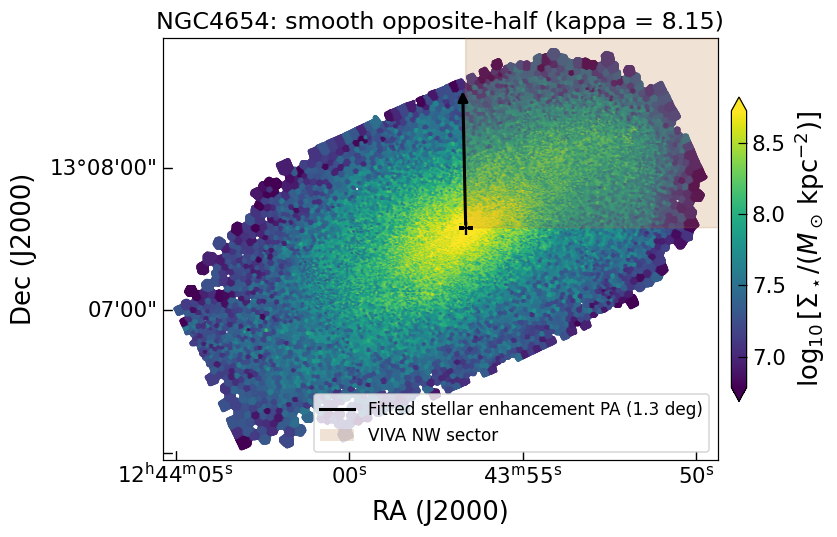

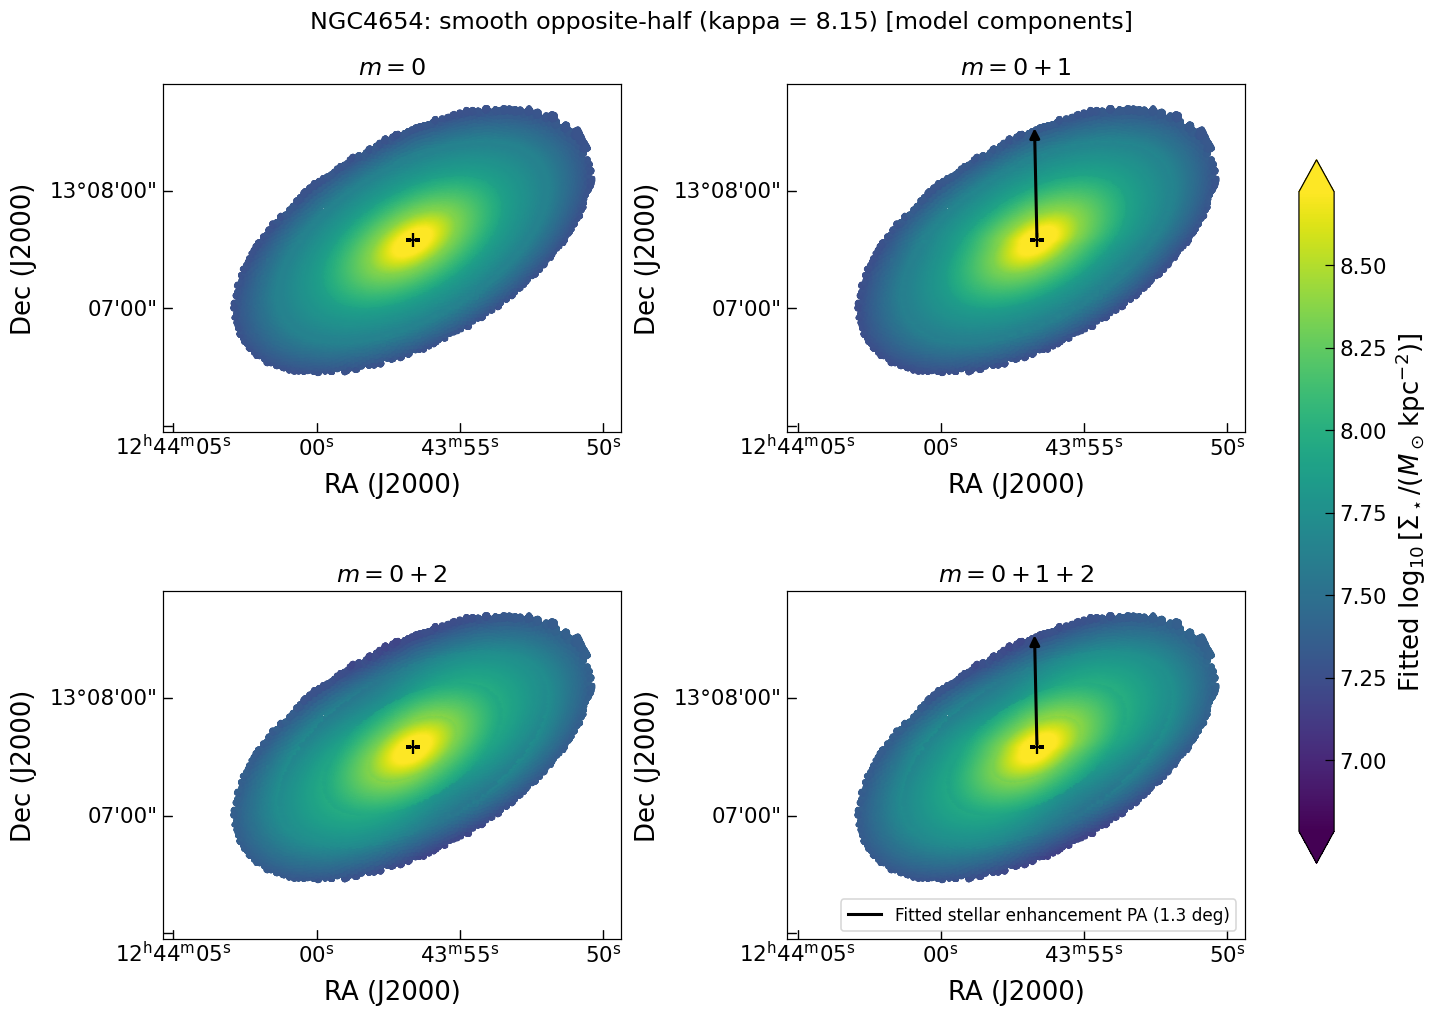

In [12]:
plot_ngc4654_arrow(half_row.PA_deg,
                   f'NGC4654: smooth opposite-half (kappa = {half_row.kappa:.2f})',
                   ngc4654_half_diagnostics)


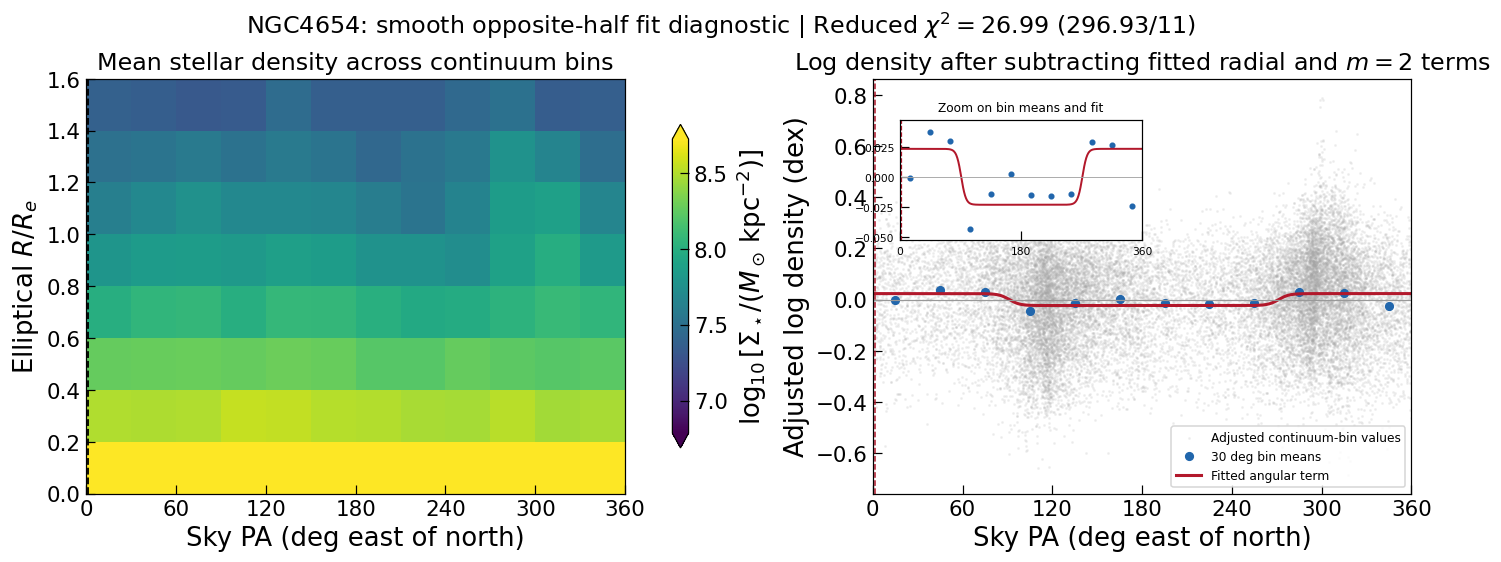

In [13]:
ngc4654_half_chi2 = plot_ngc4654_angular_diagnostic(
    ngc4654_half_diagnostics, half_row.PA_deg, half_row.amplitude_dex,
    half_row.kappa, 'NGC4654: smooth opposite-half fit diagnostic')


## Smooth opposite-sector fit

$$
\begin{aligned}
\widehat y_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{h_{\rm sec}(u_i;w,\kappa)}{h_{\rm sec}(1;w,\kappa)}}_{\text{opposite-sector term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

$$
\begin{aligned}
u_i &= \cos(\phi_i-\theta),\\
h_{\rm sec}(u;w,\kappa)
&=\tfrac12\left[
\tanh\!\bigl(\kappa[u-\cos(w/2)]\bigr)
-\tanh\!\bigl(\kappa[-u-\cos(w/2)]\bigr)
\right].
\end{aligned}
$$

Here \(w=45^\circ\) for the primary fit and \(\kappa=40\).

Use the smooth sector template from [Fourier Approach Assessment](https://chatgpt.com/c/6afba860-2ac0-83ec-8ae5-877d28f9c267). With \(c=\cos(\phi-\theta)\), set \(h(c)=[\tanh(\kappa[c-\cos\alpha])-\tanh(\kappa[-c-\cos\alpha])]/2\) and use \(A h(c)/h(1)\) as the shared angular term. The primary settings are a **45° total width per sector** (\(\alpha=22.5^\circ\)) and \(\kappa=40\). The positive and negative sectors are separated by 180°; the fitted term is near zero away from both. Normalizing to unit peak makes \(A\) the peak angular amplitude in dex and \(2A\) the central direction contrast, as in the earlier fits.

Fit the PA (east of north) over the full circle. At each PA, solve for the shared amplitude and refit the four nuisance coefficients per populated annulus (intercept, radial slope, and \(m=2\) sine and cosine). Both new models use the same equal-weight continuum bins within \(1.6R_e\) as the Fourier fit. The width check below reports all four prespecified sector widths at fixed sharpness. The 45° fit is the primary comparison regardless of which width gives the lowest RSS.

The angular diagnostic compares the adjusted log stellar density with both the continuous template and its mean over the sampled angles in each 30° bin. Its reduced \(\chi^2\) uses the local fit derivatives for amplitude and PA at fixed shape. These are descriptive fits; the narrow templates contain higher odd harmonics and can be sensitive to individual stellar structures.

In [14]:
def ngc4654_localized_shape(offset, model, width_deg, kappa):
    """Unit-peak, antipodal angular template (offset in radians)."""
    c = np.clip(np.cos(offset), -1.0, 1.0)
    if model == 'sector':
        threshold = np.cos(np.deg2rad(width_deg / 2))
        def difference(x):
            return np.tanh(kappa * (x - threshold)) - np.tanh(kappa * (-x - threshold))
        return difference(c) / difference(1.0)
    if model == 'lobes':
        if kappa == 0:
            return c  # cosine limit, with a 120 deg FWHM
        # Stable form of sinh(kappa*c) / sinh(kappa).
        z = np.abs(c)
        return (np.sign(c) * np.exp(kappa * (z - 1))
                * np.expm1(-2 * kappa * z) / np.expm1(-2 * kappa))
    raise ValueError(f'Unknown localized angular model: {model}')


def ngc4654_lobe_kappa(fwhm_deg):
    """Concentration giving the exact FWHM of the positive lobe."""
    from scipy.optimize import brentq

    if not 0 < fwhm_deg <= 120:
        raise ValueError('Lobe FWHM must be in (0, 120] deg')
    if fwhm_deg == 120:
        return 0.0
    half_width = np.deg2rad(fwhm_deg / 2)
    # At this upper bracket the exponential approximation is exactly 1/2;
    # the normalized sinh ratio is smaller.
    upper = np.log(2) / (2 * np.sin(half_width / 2)**2)
    return brentq(lambda k: ngc4654_localized_shape(half_width, 'lobes', fwhm_deg, k) - .5,
                  0.0, 2 * upper, xtol=1e-11)


def fit_ngc4654_localized(frame, model, width_deg=None, kappa=None, *, width_bounds=None):
    """Profile amplitude and annular coefficients over sky PA and optionally width."""
    from scipy.optimize import minimize, minimize_scalar, shgo

    theta, radius, y = (frame[col].to_numpy(float) for col in ('theta', 'r', 'log_sigma_star'))
    assert frame.binid.is_unique
    edges = NGC4654_FIT_EDGES
    annuli = np.unique(np.minimum(np.searchsorted(edges, radius, side='right') - 1,
                                  len(edges) - 2))
    nuisance = ngc4654_annular_design(theta, radius, annuli)
    q, r = np.linalg.qr(nuisance, mode='reduced')
    if r.shape[0] != r.shape[1] or np.linalg.cond(r) > 1e6:
        raise ValueError('Poorly conditioned annular design')
    score_y = np.einsum('ij,i->j', q, y)
    residual_y = y - np.einsum('ij,j->i', q, score_y)

    def profile(pa, width):
        concentration = ngc4654_lobe_kappa(width) if kappa is None else kappa
        column = ngc4654_localized_shape(theta - pa, model, width, concentration)
        projection = np.einsum('ij,i->j', q, column)
        column_norm2 = np.sum(column**2)
        norm2 = column_norm2 - np.sum(projection**2)
        if norm2 <= np.finfo(float).eps * column_norm2:
            raise ValueError('Localized template is degenerate with the annular design')
        score = np.sum(column * residual_y)
        return score * abs(score) / norm2, score / norm2, projection, column

    # Signed gain avoids a flat objective at negative scores. Antipodal PAs
    # flip the score, so the maximum is also the nonnegative-amplitude optimum.
    period = 2 * np.pi
    if width_bounds is None:
        def objective(pa):
            return -profile(pa, width_deg)[0]

        fit = shgo(lambda trial: objective(trial[0]), [(0.0, period)],
                   n=128, iters=2, sampling_method='simplicial')
        if not fit.success:
            raise RuntimeError(f'Localized PA search failed: {fit.message}')
        seed_pa = fit.x[0]
        step = np.deg2rad(2)
        refine = minimize_scalar(objective, method='bounded',
                                 bounds=(seed_pa - step, seed_pa + step),
                                 options={'xatol': 1e-12})
        pa = refine.x if refine.success and refine.fun < fit.fun else seed_pa
    else:
        low, high = width_bounds
        # Scale width to [0, 1] and allow local refinement across the PA seam.
        def objective(trial):
            angle, fraction = trial
            return -profile(angle, low + fraction * (high - low))[0]

        fit = shgo(objective, [(0.0, period), (0.0, 1.0)],
                   n=512, iters=2, sampling_method='sobol')
        if not fit.success:
            raise RuntimeError(f'Joint PA and width search failed: {fit.message}')
        refine = minimize(objective, fit.x, bounds=[(None, None), (0.0, 1.0)],
                          method='L-BFGS-B', options={'ftol': 1e-14})
        pa, fraction = refine.x if refine.success and refine.fun < fit.fun else fit.x
        width_deg = low + fraction * (high - low)
    pa %= period
    gain, amplitude, projection, column = profile(pa, width_deg)
    tss = np.sum((y - y.mean())**2)
    if gain <= np.finfo(float).eps * tss or amplitude <= 0:
        raise ValueError('No identifiable positive localized angular signal')
    baseline = np.linalg.solve(r, score_y - amplitude * projection)
    angular = amplitude * column
    prediction = np.einsum('ij,j->i', nuisance, baseline) + angular
    rss = np.sum((y - prediction)**2)
    np.testing.assert_allclose(np.sum(residual_y**2) - rss, gain, rtol=1e-9, atol=1e-10)

    row = dict(PA_deg=np.rad2deg(pa) % 360, amplitude_dex=amplitude,
               kappa=ngc4654_lobe_kappa(width_deg) if kappa is None else kappa,
               central_direction_contrast_dex=2 * amplitude, RSS=rss,
               RMSE_dex=np.sqrt(rss / len(y)), R2=1 - rss / tss,
               width_deg=width_deg, N_BINID=len(y))
    if width_bounds is not None:
        row['width_at_bound'] = bool(
            np.any(np.isclose(width_deg, width_bounds, atol=1e-4, rtol=0)))
    return row, frame.assign(fitted=prediction, angular=angular,
                             radial=annular_radial_term(nuisance, baseline))


def plot_ngc4654_localized(frame, row, model, title):
    width = row['width_deg']

    def shape_at_width(offset, width_deg):
        kappa = ngc4654_lobe_kappa(width_deg) if (
            model == 'lobes' and 'width_at_bound' in row) else row['kappa']
        return ngc4654_localized_shape(offset, model, width_deg, kappa)

    def shape(offset):
        return ngc4654_localized_shape(offset, model, width, row['kappa'])

    width_slope = None
    if row.get('width_at_bound') is False:
        def width_slope(offset):
            step = 1e-4  # degrees
            return (shape_at_width(offset, width + step)
                    - shape_at_width(offset, width - step)) / (2 * step)

    plot_ngc4654_arrow(row['PA_deg'], title, frame)
    return plot_ngc4654_angular_diagnostic(
        frame, row['PA_deg'], row['amplitude_dex'], row['kappa'], title + ' fit diagnostic',
        localized_shape=shape, localized_width_slope=width_slope)

,PA_deg,amplitude_dex,kappa,central_direction_contrast_dex,RSS,RMSE_dex,R2,N_BINID,PA_minus_primary_deg
width_deg,,,,,,,,,
30.0,296.456262,0.047445,40.0,0.094889,701.368618,0.175387,0.849683,22801,-0.998453
45.0,297.454715,0.038058,40.0,0.076116,702.787945,0.175564,0.849379,22801,0.000000
60.0,293.794431,0.031105,40.0,0.062210,705.567822,0.175911,0.848783,22801,-3.660285
90.0,322.070026,0.023667,40.0,0.047335,709.651361,0.176419,0.847908,22801,24.615310


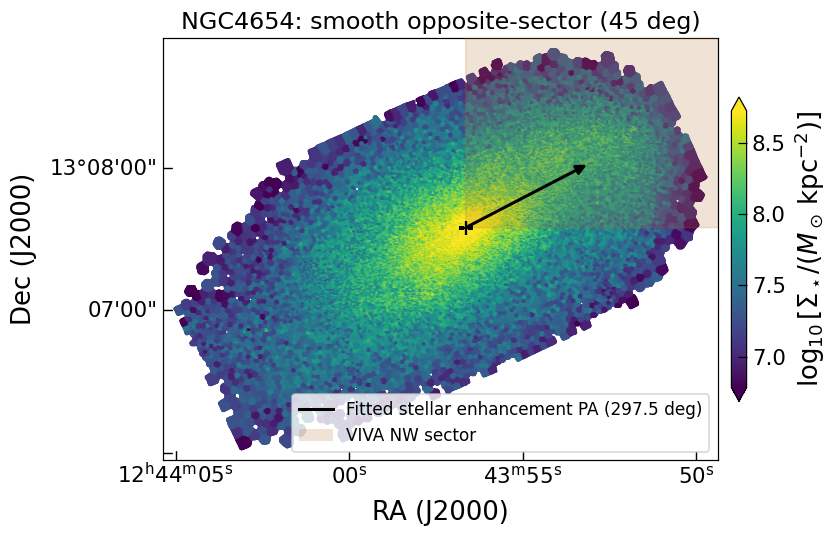

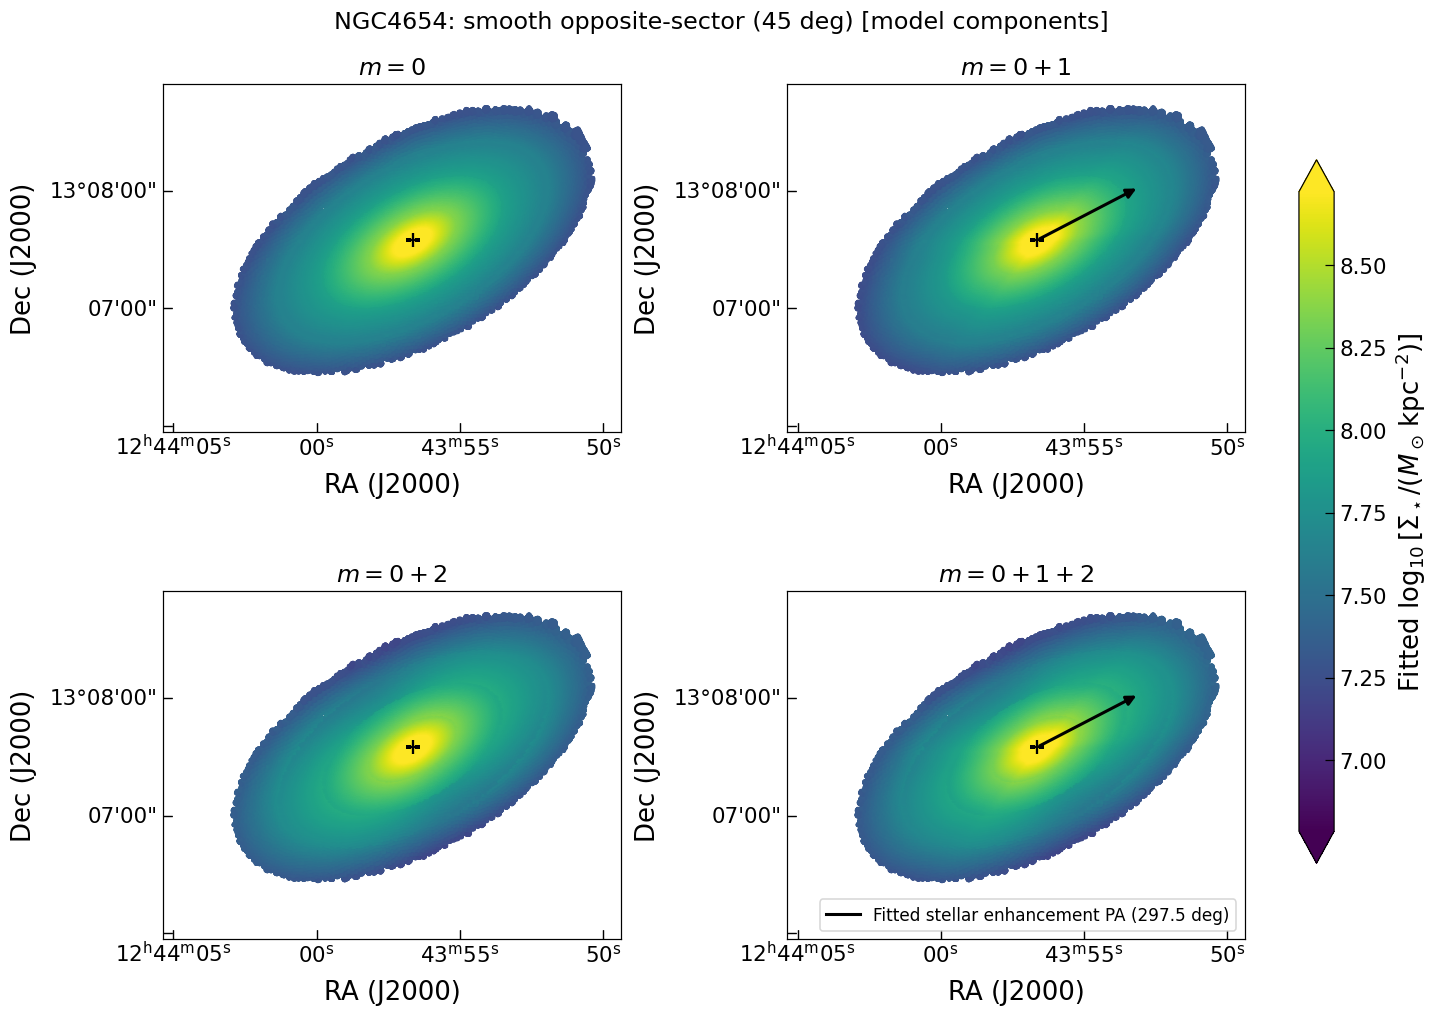

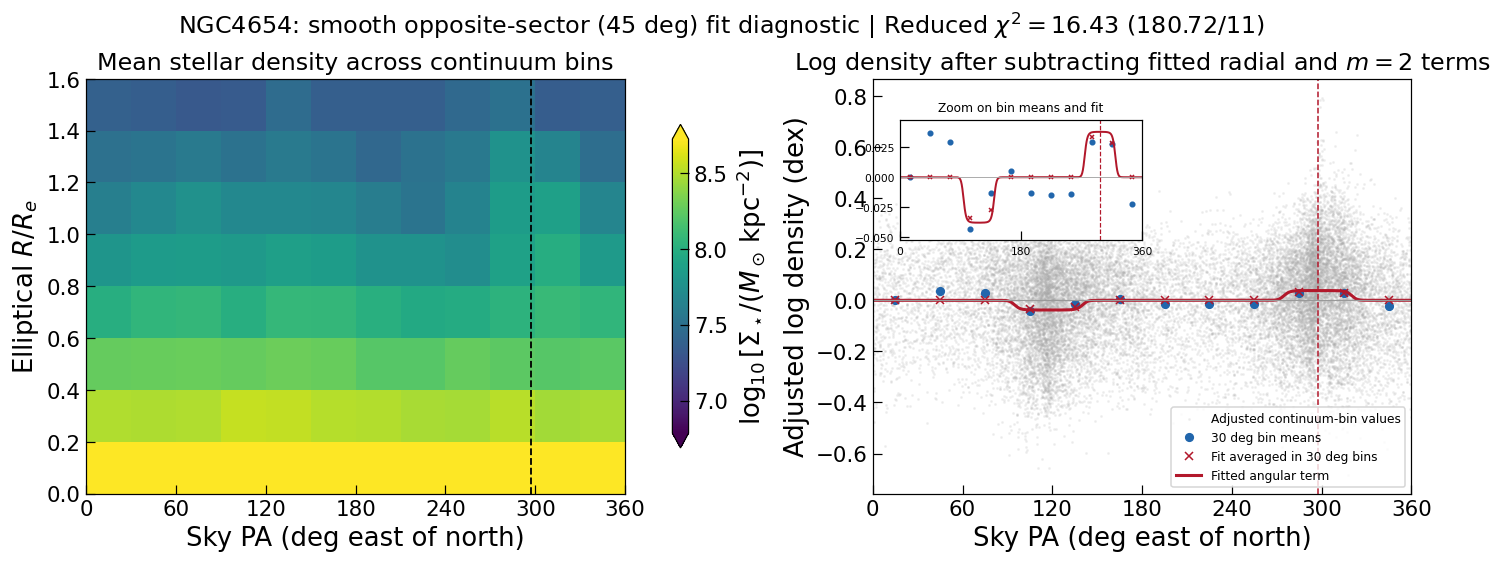

In [15]:
ngc4654_sector_row, ngc4654_sector_diagnostics = fit_ngc4654_localized(
    ngc4654_cosine_diagnostics, 'sector', width_deg=45.0, kappa=40.0)
sector_width_rows = [
    ngc4654_sector_row if width == 45 else
    fit_ngc4654_localized(ngc4654_cosine_diagnostics, 'sector', width, 40.0)[0]
    for width in (30.0, 45.0, 60.0, 90.0)
]
ngc4654_sector_width_check = pd.DataFrame(sector_width_rows).set_index('width_deg')
ngc4654_sector_width_check['PA_minus_primary_deg'] = (
    (ngc4654_sector_width_check.PA_deg - ngc4654_sector_row['PA_deg'] + 180) % 360 - 180)
display(ngc4654_sector_width_check.round(6))

ngc4654_sector_chi2 = plot_ngc4654_localized(
    ngc4654_sector_diagnostics, ngc4654_sector_row, 'sector',
    'NGC4654: smooth opposite-sector (45 deg)')

## Gaussian-like angular lobes with fixed 45° FWHM

$$
\begin{aligned}
\widehat y_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{\sinh[\kappa_{45}\cos(\phi_i-\theta)]}{\sinh\kappa_{45}}}_{\text{opposite-lobe term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

The 45° width enters through the fixed concentration
$$
\kappa_{45}=\frac{\ln 2}{1-\cos(45^\circ/2)}\simeq9.1059.
$$
The half-maximum points are approximately \(\theta\pm22.5^\circ\). This choice uses the near-peak exponential approximation to the normalized sinh profile. The fit varies the shared amplitude \(A\), sky PA \(\theta\), and annular coefficients with \(\kappa_{45}\) fixed.

The table reports wrapped PA shifts and in-sample RSS changes relative to the Fourier cosine. The narrow shapes are sensitivity checks for the fitted direction. The table and plots do not measure the significance of the new asymmetry terms or establish their physical origin.

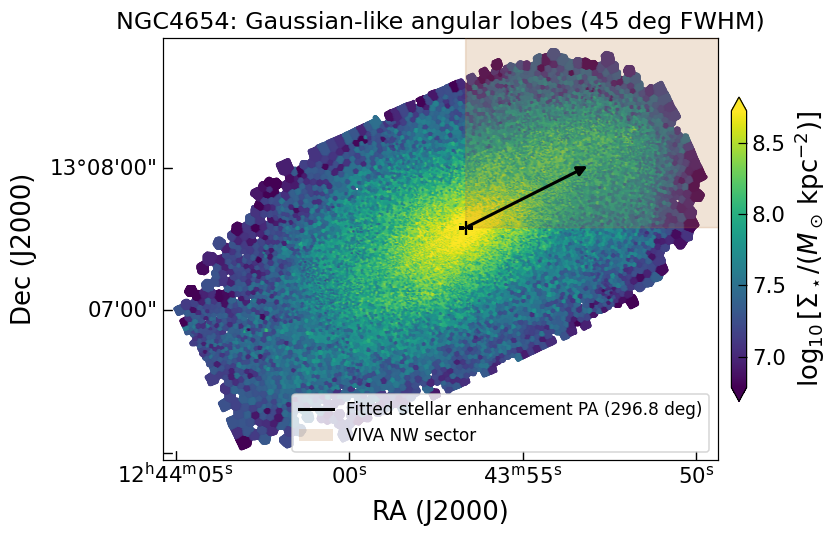

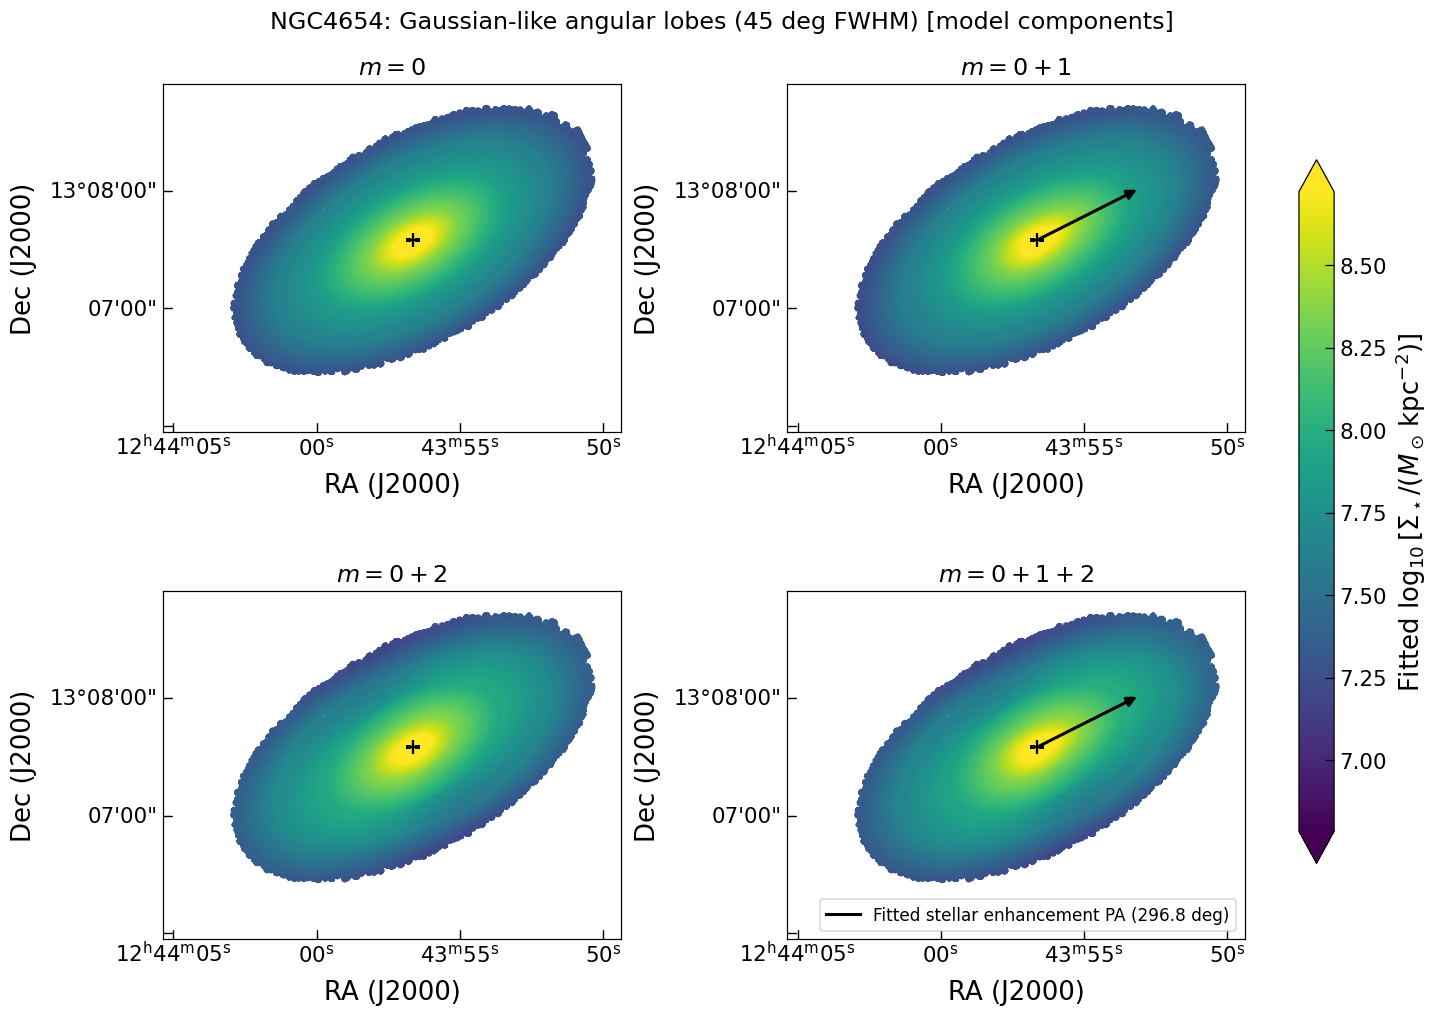

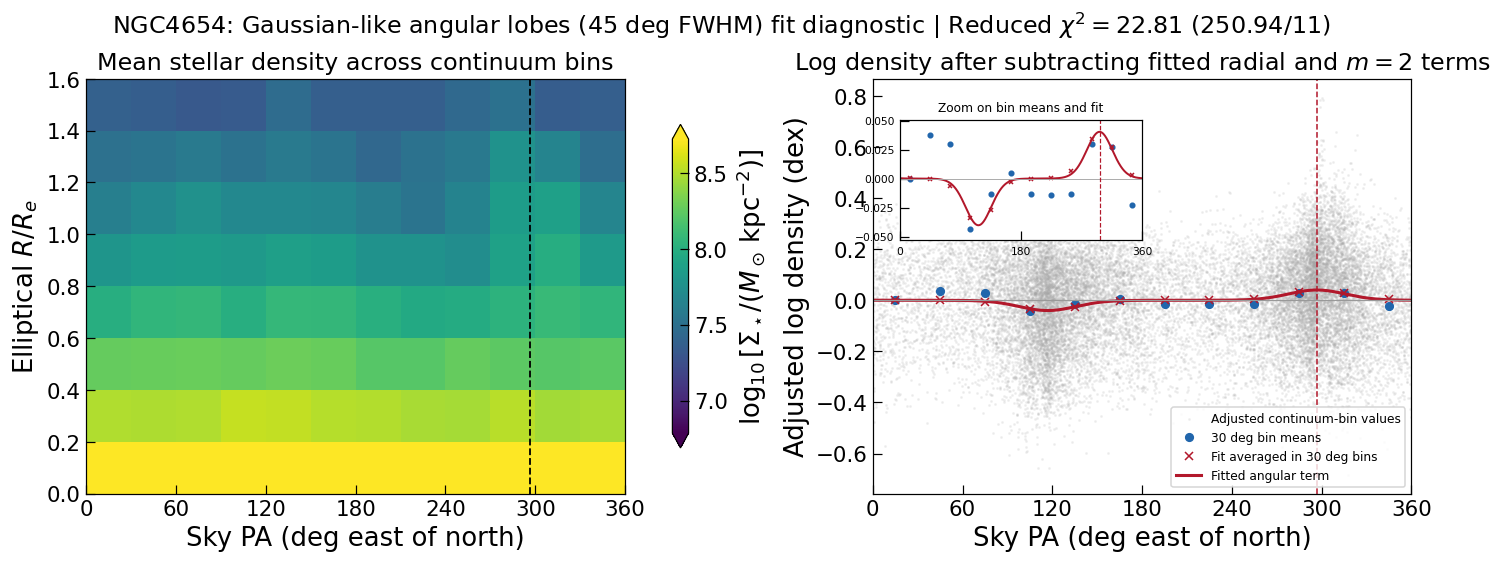

,PA_deg,amplitude_dex,kappa,central_direction_contrast_dex,RSS,RMSE_dex,R2,N_BINID,width_deg,PA_minus_cosine_deg,RSS_reduction_vs_cosine_pct,angular_reduced_chi2
model,,,,,,,,,,,,
Fourier cosine,320.409246,0.021500,0.000000,0.043000,711.618070,0.176663,0.847486,22801,NaN,0.000000,0.000000,33.056348
Smooth opposite-half,1.257794,0.023336,8.147481,0.046672,707.447265,0.176145,0.848380,22801,NaN,40.848548,0.586102,26.993927
Smooth opposite-sector,297.454715,0.038058,40.000000,0.076116,702.787945,0.175564,0.849379,22801,45.0,-22.954531,1.240852,16.428696
Gaussian-like angular lobes,296.775475,0.040247,9.105924,0.080494,703.776390,0.175687,0.849167,22801,45.0,-23.633771,1.101951,22.812451


In [16]:
lobe_fwhm_deg = 45.0
lobe_kappa = np.log(2) / (1 - np.cos(np.deg2rad(lobe_fwhm_deg / 2)))
ngc4654_lobe_row, ngc4654_lobe_diagnostics = fit_ngc4654_localized(
    ngc4654_cosine_diagnostics, 'lobes', width_deg=lobe_fwhm_deg, kappa=lobe_kappa)
ngc4654_lobe_chi2 = plot_ngc4654_localized(
    ngc4654_lobe_diagnostics, ngc4654_lobe_row, 'lobes',
    'NGC4654: Gaussian-like angular lobes (45 deg FWHM)')

ngc4654_localized_comparison = pd.concat([
    ngc4654_angular_comparison.assign(N_BINID=ngc4654_angular_bin_count),
    pd.DataFrame([ngc4654_sector_row, ngc4654_lobe_row],
                 index=['Smooth opposite-sector', 'Gaussian-like angular lobes']),
]).rename_axis('model')
ngc4654_localized_comparison['PA_minus_cosine_deg'] = (
    (ngc4654_localized_comparison.PA_deg - cosine_row.PA_deg + 180) % 360 - 180)
ngc4654_localized_comparison['RSS_reduction_vs_cosine_pct'] = (
    100 * (1 - ngc4654_localized_comparison.RSS / cosine_row.RSS))
ngc4654_localized_comparison['angular_reduced_chi2'] = [
    item['reduced_chi2'] for item in (ngc4654_cosine_chi2, ngc4654_half_chi2,
                                    ngc4654_sector_chi2, ngc4654_lobe_chi2)
]
display(ngc4654_localized_comparison.round(6))

## Smooth opposite-sector fit with free total width

$$
\begin{aligned}
\widehat y_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{h_{\rm sec}(u_i;w,\kappa)}{h_{\rm sec}(1;w,\kappa)}}_{\text{opposite-sector term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

$$
\begin{aligned}
u_i &= \cos(\phi_i-\theta),\\
h_{\rm sec}(u;w,\kappa)
&=\tfrac12\left[
\tanh\!\bigl(\kappa[u-\cos(w/2)]\bigr)
-\tanh\!\bigl(\kappa[-u-\cos(w/2)]\bigr)
\right].
\end{aligned}
$$

The fit varies \(A\), \(\theta\), and \(w\), with \(5^\circ\le w\le180^\circ\) and \(\kappa=40\).

Fit the sky PA and total width per sector jointly, using the same unit-peak template and continuum bins as the 45° sector fit. Keep \(\kappa=40\) and allow a nominal width from 5° to 180°. The width sets the tanh transition threshold. The finite transition sharpness also affects the measured half-maximum width, especially for narrow sectors.

For these two free-width sections, the angular reduced \(\chi^2\) includes the local derivative with respect to width when the solution is interior. If the width reaches a bound, the diagnostic is conditional on that boundary width. Changes in RSS describe the in-sample effect of fitting one more parameter.

,PA_deg,amplitude_dex,kappa,central_direction_contrast_dex,RSS,RMSE_dex,R2,width_deg,N_BINID,width_at_bound
Free-width opposite-sector,296.512645,0.045778,40.0,0.091556,701.311723,0.175379,0.849695,32.801537,22801,False


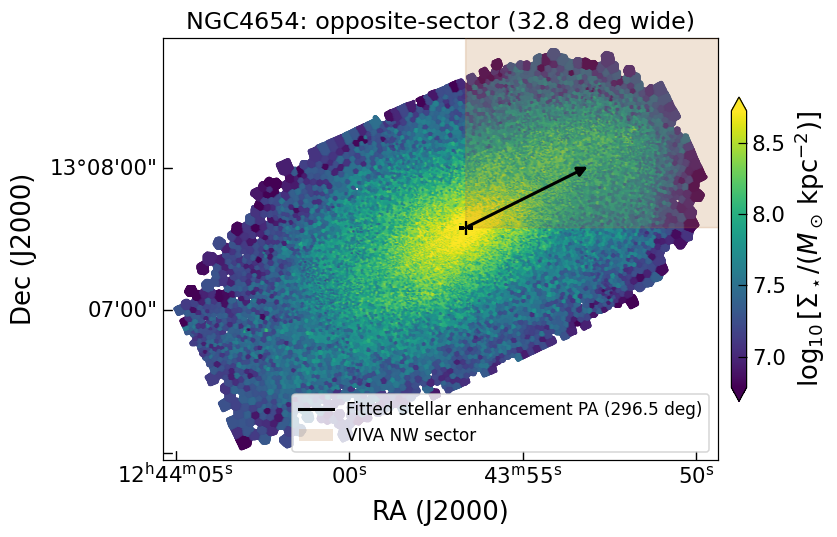

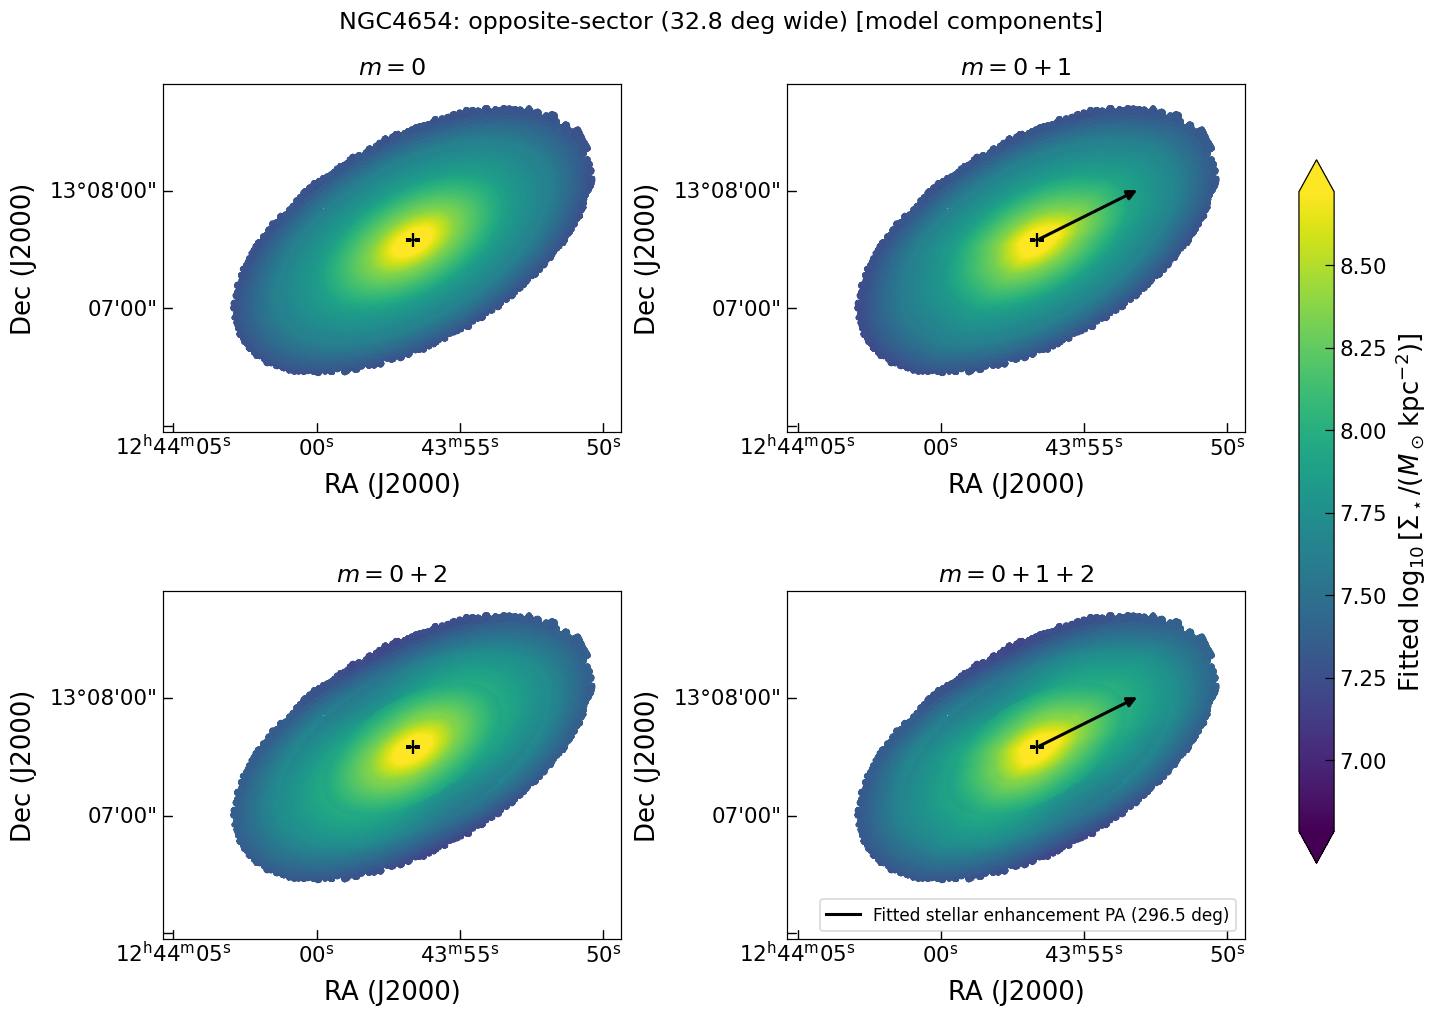

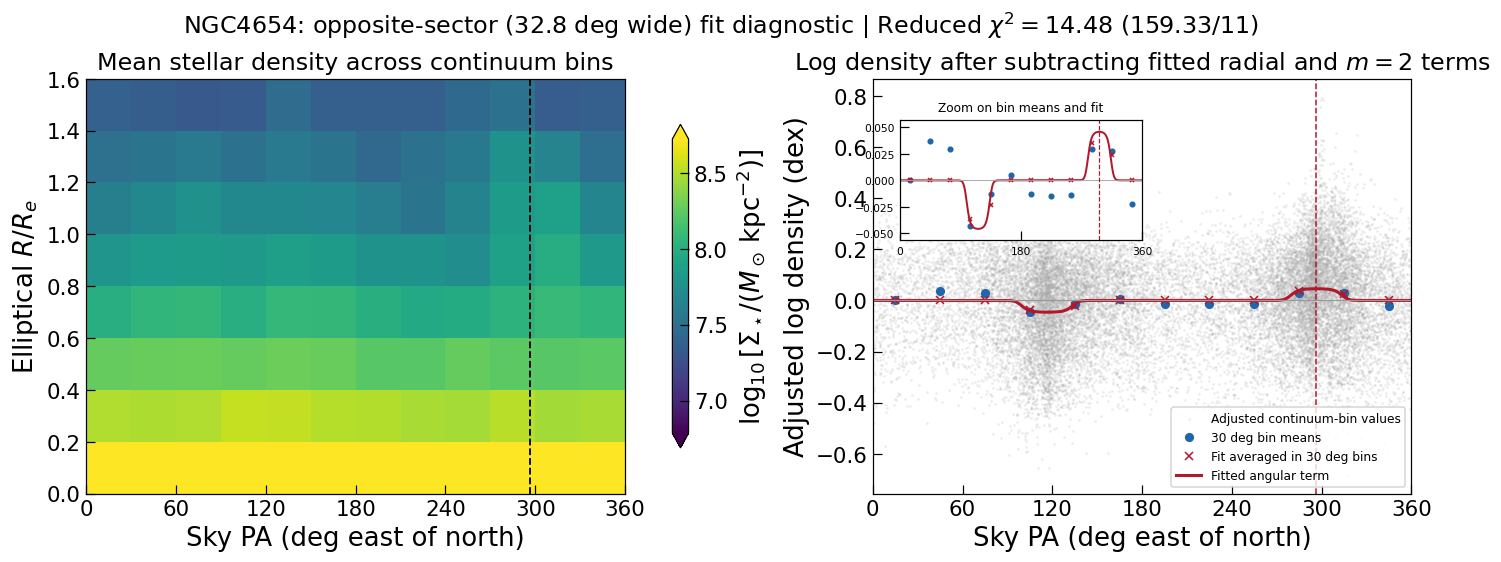

In [17]:
sector_free_bounds_deg = (5.0, 180.0)
ngc4654_free_sector_row, ngc4654_free_sector_diagnostics = fit_ngc4654_localized(
    ngc4654_cosine_diagnostics, 'sector', kappa=40.0, width_bounds=sector_free_bounds_deg)
display(pd.DataFrame([ngc4654_free_sector_row], index=['Free-width opposite-sector']).round(6))
ngc4654_free_sector_chi2 = plot_ngc4654_localized(
    ngc4654_free_sector_diagnostics, ngc4654_free_sector_row, 'sector',
    f"NGC4654: opposite-sector ({ngc4654_free_sector_row['width_deg']:.1f} deg wide)")

## Gaussian-like angular lobes with free FWHM

$$
\begin{aligned}
\widehat y_i
={}&\underbrace{\alpha_a+\beta_a(r_i-r_a)}_{m=0}
+\underbrace{A\,\frac{\sinh[\kappa(w)\cos(\phi_i-\theta)]}{\sinh\kappa(w)}}_{\text{opposite-lobe term}}\\
&+\underbrace{c_{2,a}\cos(2\phi_i)+s_{2,a}\sin(2\phi_i)}_{m=2}.
\end{aligned}
$$

At each trial FWHM \(w\), compute \(\kappa(w)\) from
$$
\frac{\sinh[\kappa(w)\cos(w/2)]}{\sinh\kappa(w)}=\frac12,
\qquad 5^\circ\le w\le120^\circ.
$$
At \(w=120^\circ\), use the cosine limit at \(\kappa=0\).

Fit \(A\), \(\theta\), and \(w\) jointly with the annular coefficients on the same bins. The trial width \(w\) changes the angular term through \(\kappa(w)\), evaluated at every trial width.

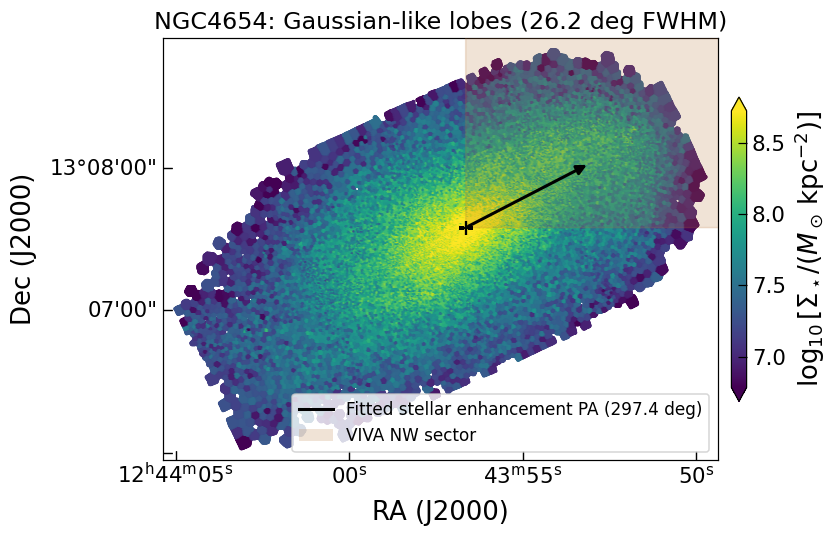

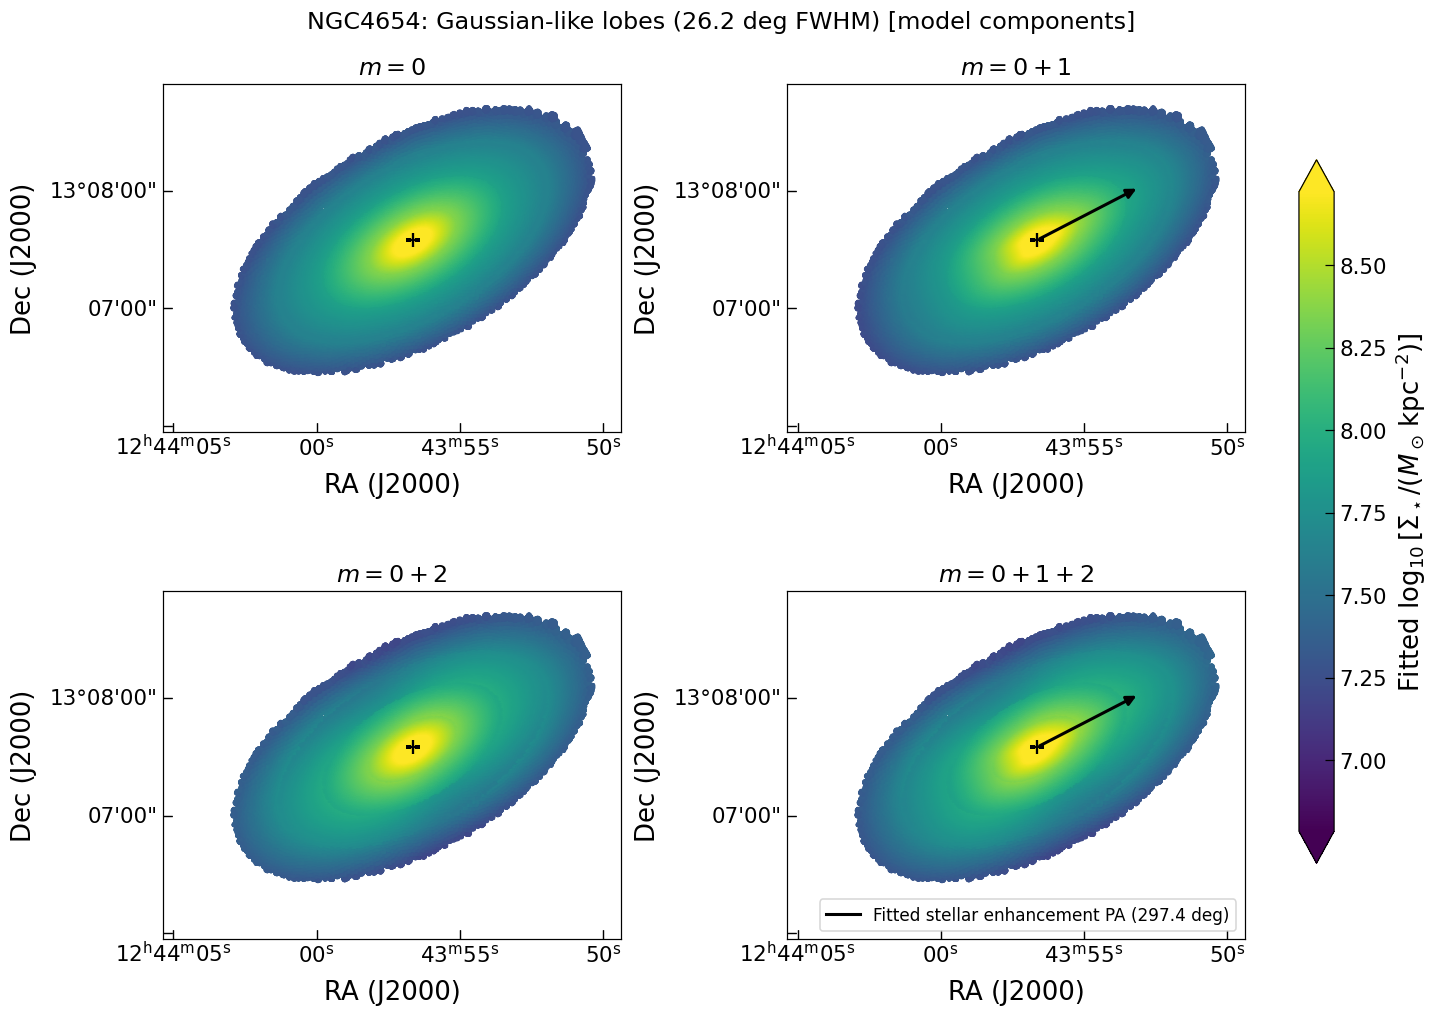

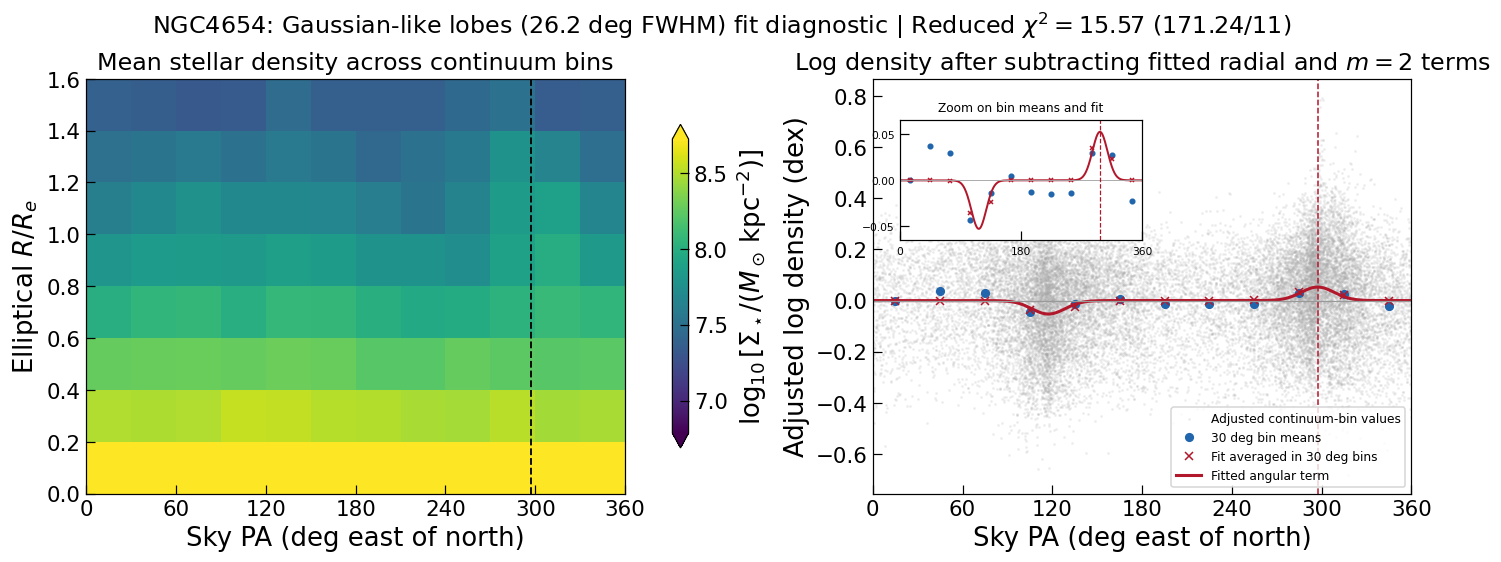

,PA_deg,amplitude_dex,kappa,central_direction_contrast_dex,RSS,RMSE_dex,R2,N_BINID,width_deg,PA_minus_cosine_deg,RSS_reduction_vs_cosine_pct,angular_reduced_chi2,width_at_bound,width_definition
model,,,,,,,,,,,,,,
Fourier cosine,320.409246,0.021500,0.000000,0.043000,711.618070,0.176663,0.847486,22801,NaN,0.000000,0.000000,33.056348,NaN,
Smooth opposite-half,1.257794,0.023336,8.147481,0.046672,707.447265,0.176145,0.848380,22801,NaN,40.848548,0.586102,26.993927,NaN,
Smooth opposite-sector,297.454715,0.038058,40.000000,0.076116,702.787945,0.175564,0.849379,22801,45.000000,-22.954531,1.240852,16.428696,NaN,Total sector width
Gaussian-like angular lobes,296.775475,0.040247,9.105924,0.080494,703.776390,0.175687,0.849167,22801,45.000000,-23.633771,1.101951,22.812451,NaN,Lobe FWHM
Free-width opposite-sector,296.512645,0.045778,40.000000,0.091556,701.311723,0.175379,0.849695,22801,32.801537,-23.896601,1.448297,14.484186,False,Total sector width
Free-FWHM Gaussian-like lobes,297.356990,0.052837,26.721540,0.105674,701.341718,0.175383,0.849689,22801,26.157299,-23.052256,1.444082,15.567340,False,Lobe FWHM


In [18]:
lobe_free_bounds_deg = (5.0, 120.0)
ngc4654_free_lobe_row, ngc4654_free_lobe_diagnostics = fit_ngc4654_localized(
    ngc4654_cosine_diagnostics, 'lobes', width_bounds=lobe_free_bounds_deg)
ngc4654_free_lobe_chi2 = plot_ngc4654_localized(
    ngc4654_free_lobe_diagnostics, ngc4654_free_lobe_row, 'lobes',
    f"NGC4654: Gaussian-like lobes ({ngc4654_free_lobe_row['width_deg']:.1f} deg FWHM)")

free_rows = pd.DataFrame([ngc4654_free_sector_row, ngc4654_free_lobe_row],
                         index=['Free-width opposite-sector', 'Free-FWHM Gaussian-like lobes'])
free_rows['angular_reduced_chi2'] = [ngc4654_free_sector_chi2['reduced_chi2'],
                                    ngc4654_free_lobe_chi2['reduced_chi2']]
ngc4654_free_width_comparison = pd.concat([
    ngc4654_localized_comparison, free_rows,
]).rename_axis('model')
ngc4654_free_width_comparison['width_definition'] = [
    '', '', 'Total sector width', 'Lobe FWHM', 'Total sector width', 'Lobe FWHM',
]
ngc4654_free_width_comparison['PA_minus_cosine_deg'] = (
    (ngc4654_free_width_comparison.PA_deg - cosine_row.PA_deg + 180) % 360 - 180)
ngc4654_free_width_comparison['RSS_reduction_vs_cosine_pct'] = (
    100 * (1 - ngc4654_free_width_comparison.RSS / cosine_row.RSS))
display(ngc4654_free_width_comparison.round(6))